# Week 7: Text and Multimodal AI (Project 2)

**Author**: Muhammad Umar Khan  
**Date**: 31 October, 2026  
**Course**: Introduction to Applied AI  |  **Domain**: brain-tumour MRI (my Week 6 model)

## What this notebook does, end to end

This notebook gives my Project 2 system the ability to *read*. Every component gets a number, so each result below can be checked against the printed output of its cell.

| Part | Topic | Key equation | Measured result (from my run) |
|---|---|---|---|
| 1 | TF-IDF by hand | smooth IDF, L2 norm, cosine | hand = scikit-learn; cosine(d2, d3) = 0.544 |
| 2 | SMS spam: word vs character n-grams | logistic regression, macro-F1 | macro-F1 0.974 (word) vs 0.982 (char) |
| 3 | NER against a gold set, then entity ruler | entity-level P, R, F1 | provided set 0.533 to 0.875; my held-out set 0.722 to 1.000 |
| 4 | Regex fields with negative tests | pattern tests, word boundaries | 5/5 lab tests, 8/8 domain tests (5 negative) |
| 5 | Character error rate and OCR repair | CER = (S + D + I) / N | lab pairs 0.062, 0.059, 0.143 to 0.000; invoice 0.000 |
| 6 | Image + text case record with privacy | late fusion, masking first | REFER, P(tumor) = 0.996, no PII in the JSON |
| 7 | README, LinkedIn post, Check Your Understanding | | six answers with working |

## Before you press Run All

| Setting / input | Value |
|---|---|
| Internet | **On** (EasyOCR downloads about 100 MB on first use) |
| SMS dataset | `/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv` |
| Week 6 model | `/kaggle/input/models/umarkhan360/week6-model/pytorch/default/1/week6_model.pt` |
| Week 6 images (for Part 6) | `/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset` (add it with **Add Input**) |

Every path below first tries the exact path above and then searches `/kaggle/input` for the file, so a slightly different folder name will not break the notebook.

**How each section is laid out:** a heading and description *before* the cell (what it does and why), the cell itself with its real output, then a **Calculations** block *after* it that re-derives the printed numbers by hand.

## Formula sheet (all equations used in this notebook)

**Text as numbers**

| Name | Equation |
|---|---|
| Smooth IDF (scikit-learn) | $\text{idf}(t) = \ln\!\left(\dfrac{1+N}{1+\text{df}(t)}\right) + 1$ |
| TF-IDF weight | $w_{t,d} = \text{tf}(t,d)\cdot \text{idf}(t)$ |
| L2 normalisation | $\mathbf{v}_d = \dfrac{\mathbf{w}_d}{\lVert \mathbf{w}_d \rVert_2}, \quad \lVert \mathbf{w}_d \rVert_2 = \sqrt{\sum_t w_{t,d}^2}$ |
| Sublinear tf | $\text{tf}' = 1 + \ln(\text{tf})$ |
| Cosine similarity | $\cos(\mathbf{a},\mathbf{b}) = \dfrac{\mathbf{a}\cdot\mathbf{b}}{\lVert\mathbf{a}\rVert\,\lVert\mathbf{b}\rVert}$ (equals $\mathbf{a}\cdot\mathbf{b}$ when both have length 1) |

**Classification and metrics**

| Name | Equation |
|---|---|
| Logistic regression | $P(\text{spam}\mid x) = \sigma(\mathbf{w}\cdot\mathbf{x} + b), \quad \sigma(z) = \dfrac{1}{1+e^{-z}}, \quad z = \ln\dfrac{p}{1-p}$ |
| Balanced class weight | $c_k = \dfrac{n_{\text{samples}}}{K \cdot n_k}$ |
| Precision, recall, F1 | $P = \dfrac{TP}{TP+FP},\quad R = \dfrac{TP}{TP+FN},\quad F_1 = \dfrac{2PR}{P+R}$ |
| Macro-F1 | $\text{macro-}F_1 = \dfrac{1}{K}\sum_{k} F_{1,k}$ |
| Entity-level scores | same $P, R, F_1$, but a prediction is a true positive only if **exact text AND label** match the gold entity |

**OCR and fusion**

| Name | Equation |
|---|---|
| Character error rate | $\text{CER} = \dfrac{S + D + I}{N}$ (Levenshtein edits / reference length) |
| Softmax (image model) | $p_c = \dfrac{e^{z_c}}{\sum_j e^{z_j}}$ |
| Late fusion | $p = w\cdot p_{\text{image}} + (1-w)\cdot p_{\text{text}}$ |

## Setup: imports, spaCy and helper functions

**What this cell does.** Loads every library the notebook needs in one place (so a failing import can never break a later cell), loads the spaCy English model `en_core_web_sm` (and downloads it if it is missing), and defines two helpers:

- `show(md_text)` renders a markdown string as cell output (used by the "Write it" cells);
- `first_existing(primary, pattern)` uses the exact Kaggle path if it exists and otherwise searches `/kaggle/input`, so a different folder name does not cause a `FileNotFoundError`.

**Expected output:** the spaCy and torch versions. My run printed `spaCy 3.8.16 | torch 2.11.0+cpu`, so the session is CPU-only (no GPU).

In [25]:
import os, re, sys, json, glob, subprocess
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import spacy
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageDraw, ImageFont
from torchvision import models, transforms
from IPython.display import display, Markdown
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score)

try:
    nlp = spacy.load('en_core_web_sm')           # preinstalled on Kaggle
except OSError:                                   # model missing: download once
    subprocess.run([sys.executable, '-m', 'spacy', 'download', 'en_core_web_sm'],
                   check=True)
    nlp = spacy.load('en_core_web_sm')
print('spaCy', spacy.__version__, '| torch', torch.__version__)

def show(md_text):
    """Render a markdown string as the cell output."""
    display(Markdown(md_text))

def first_existing(primary, pattern, what='file'):
    """Use the exact path if it exists, otherwise search /kaggle/input for it."""
    if os.path.exists(primary):
        return primary
    hits = sorted(glob.glob(pattern, recursive=True))
    if hits:
        print(f'{what}: {primary} not found, using {hits[0]}')
        return hits[0]
    raise FileNotFoundError(
        f'{what} not found. Add it with "Add Input" and copy the exact path '
        f'(tried {primary} and {pattern}).')

spaCy 3.8.16 | torch 2.11.0+cpu


## Part 1: TF-IDF by Hand (10 min)

**Goal.** Before trusting a library, reproduce it. This cell builds the TF-IDF table for three tiny messages with scikit-learn, then recomputes document d1 by hand and asserts the two agree.

**The three messages:** d1 = "win free cash now", d2 = "call me now", d3 = "free call now" (N = 3).

**Equations used**

$$\text{idf}(t) = \ln\!\left(\frac{1+N}{1+\text{df}(t)}\right)+1 \qquad\quad \mathbf{v}_d = \frac{\text{tf}\cdot\text{idf}}{\lVert \text{tf}\cdot\text{idf}\rVert_2} \qquad\quad \cos(d_2,d_3)=\mathbf{v}_{d_2}\cdot\mathbf{v}_{d_3}$$

Words that appear in many documents get a low IDF (they cannot tell documents apart); rare words get a boost. The `+1` keeps a word that appears everywhere from getting weight 0.

In [26]:
docs = ['win free cash now', 'call me now', 'free call now']
vec = TfidfVectorizer()                 # smooth idf + L2 normalization
X = vec.fit_transform(docs)
table = pd.DataFrame(X.toarray(), columns=vec.get_feature_names_out(),
                     index=['d1', 'd2', 'd3'])
print(table.round(3))

# Reproduce d1 by hand: idf = ln((1 + N) / (1 + df)) + 1
N = 3
idf = {'win': np.log(4 / 2) + 1, 'free': np.log(4 / 3) + 1,
       'cash': np.log(4 / 2) + 1, 'now': np.log(4 / 4) + 1}
v = np.array(list(idf.values()))       # tf = 1 for each word in d1
by_hand = {w: round(float(x), 3) for w, x in zip(idf, v / np.linalg.norm(v))}
print('by hand d1:', by_hand)
print('raw idf   :', {w: round(float(x), 4) for w, x in idf.items()})

lib_d1 = {w: round(float(table.loc['d1', w]), 3) for w in idf}
assert lib_d1 == by_hand, 'hand calculation and scikit-learn disagree'
print('hand == library for d1: OK')

# Cosine similarity d2 vs d3 (vectors already have length 1, so just the dot product)
A = X.toarray()
cos_d2_d3 = float(A[1] @ A[2])
print(f'cosine(d2, d3) = {cos_d2_d3:.3f}   (slide 10: 0.54)')

     call   cash   free    me    now    win
d1  0.000  0.584  0.445  0.00  0.345  0.584
d2  0.548  0.000  0.000  0.72  0.425  0.000
d3  0.620  0.000  0.620  0.00  0.481  0.000
by hand d1: {'win': 0.584, 'free': 0.445, 'cash': 0.584, 'now': 0.345}
raw idf   : {'win': 1.6931, 'free': 1.2877, 'cash': 1.6931, 'now': 1.0}
hand == library for d1: OK
cosine(d2, d3) = 0.544   (slide 10: 0.54)


### Calculations: Part 1 (checked against the printed output)

**Step 1: document frequency and smooth IDF** (N = 3, so $1+N = 4$)

| Word | df | $\ln(4/(1+\text{df}))+1$ | idf |
|---|---|---|---|
| win | 1 | $\ln(4/2)+1 = 0.6931+1$ | **1.6931** |
| free | 2 | $\ln(4/3)+1 = 0.2877+1$ | **1.2877** |
| cash | 1 | $\ln(4/2)+1$ | **1.6931** |
| call | 2 | $\ln(4/3)+1$ | **1.2877** |
| me | 1 | $\ln(4/2)+1$ | **1.6931** |
| now | 3 | $\ln(4/4)+1 = 0+1$ | **1.0000** |

"now" is in all three messages, so it gets the lowest weight (the floor of 1). This matches the printed `raw idf: {'win': 1.6931, 'free': 1.2877, 'cash': 1.6931, 'now': 1.0}`.

**Step 2: d1 by hand** (each word appears once, so tf = 1 and the raw vector equals the idf values)

$$\mathbf{w}_{d_1} = (1.6931,\;1.2877,\;1.6931,\;1.0000)\quad\text{for (win, free, cash, now)}$$

$$\lVert\mathbf{w}_{d_1}\rVert = \sqrt{1.6931^2+1.2877^2+1.6931^2+1.0^2} = \sqrt{2.8668+1.6582+2.8668+1.0000} = \sqrt{8.3918} = 2.8969$$

| Word | $w/2.8969$ | Printed |
|---|---|---|
| win | 0.5845 | **0.584** |
| free | 0.4445 | **0.445** |
| cash | 0.5845 | **0.584** |
| now | 0.3452 | **0.345** |

These equal the scikit-learn row for d1 (the cell prints `hand == library for d1: OK`).

**Step 3: the other two vectors**

- d2 = (call 1.2877, me 1.6931, now 1.0): length $\sqrt{1.6582+2.8668+1} = \sqrt{5.525} = 2.3505$, so call 0.548, me 0.720, now 0.425.
- d3 = (call 1.2877, free 1.2877, now 1.0): length $\sqrt{1.6582+1.6582+1} = \sqrt{4.3164} = 2.0776$, so call 0.620, free 0.620, now 0.481.

**Step 4: cosine similarity** (vectors have length 1, so cosine = dot product over shared words)

$$\cos(d_2,d_3) = \underbrace{0.548\times0.620}_{\text{call}} + \underbrace{0.425\times0.481}_{\text{now}} = 0.3398 + 0.2044 = \mathbf{0.544}$$

The printed value is `cosine(d2, d3) = 0.544`, which matches the 0.54 on slide 10. Other pairs: $\cos(d_1,d_3) = 0.445\times0.620 + 0.345\times0.481 = 0.276+0.166 = 0.44$ (shared: free, now) and $\cos(d_1,d_2) = 0.345\times0.425 = 0.15$ (shared: now only).

**Interpretation.** "call" contributes 0.340 to the d2/d3 similarity but "now" only 0.204 because "now" is in every message. That is exactly why IDF matters for search, duplicate detection and the retrieval step planned for Week 10.

## Part 2: Text Classification (20 min)

Week 2's logistic regression, now with words as features: `TF-IDF -> Logistic Regression` is a strong, fast, interpretable baseline for short texts.

### Task 2.1: Load and inspect the SMS Spam Collection

**What this cell does.** Reads `spam.csv` (the file is Latin-1, not UTF-8, hence `encoding='latin-1'`), keeps the label and text columns, makes a 0/1 target `y` (spam = 1) and prints the class balance. It also prints the accuracy of the useless classifier that always says "ham", the number any real model must beat.

**Equations**

$$\text{spam share} = \frac{n_{\text{spam}}}{n_{\text{total}}} \qquad\quad \text{accuracy}_{\text{always ham}} = \frac{n_{\text{ham}}}{n_{\text{total}}} = 1-\text{spam share}$$

In [27]:
path = first_existing(
    '/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv',
    '/kaggle/input/**/spam.csv', what='SMS dataset')
sms = pd.read_csv(path, encoding='latin-1')[['v1', 'v2']]   # file is Latin-1, not UTF-8
sms.columns = ['label', 'text']
sms['y'] = (sms['label'] == 'spam').astype(int)
print(sms['label'].value_counts().to_string())
print(f"Spam share: {sms['y'].mean():.3f}   "
      f"'always ham' accuracy: {1 - sms['y'].mean():.3f}")

label
ham     4825
spam     747
Spam share: 0.134   'always ham' accuracy: 0.866


### Calculations: Task 2.1

$$n_{\text{total}} = 4825 + 747 = 5572$$

$$\text{spam share} = \frac{747}{5572} = 0.1341 \;\;(\text{printed } 0.134) \qquad \text{accuracy}_{\text{always ham}} = \frac{4825}{5572} = 0.8659 \;\;(\text{printed } 0.866)$$

**Why accuracy is the wrong metric here.** A model that never flags anything already scores 86.6%, so I report **macro-F1** and the **spam precision and recall** instead. Both kinds of error also matter: a false negative lets a scam through, and a false positive hides a real message from a bank or a family member.

### Task 2.2: Word n-gram classifier

**What this cell does.** Splits the data 80/20 (`random_state=42`, stratified so the 13.4% spam share is the same in both parts), then trains a pipeline of `TfidfVectorizer` (words and word pairs) and `LogisticRegression`. It prints the classification report and draws the confusion matrix.

**Why each setting**

| Setting | Reason |
|---|---|
| `ngram_range=(1, 2)` | "call now" means more than "call" + "now" |
| `min_df=2` | drop words seen only once (Zipf's long tail) |
| `sublinear_tf=True` | use $1+\ln(\text{tf})$: the 10th "free" adds little |
| `class_weight='balanced'` | spam is only 13.4%, so errors on spam are weighted up |

**Equations**

$$P(\text{spam}\mid x)=\sigma(\mathbf{w}\cdot\mathbf{x}+b) \qquad \text{tf}'=1+\ln(\text{tf}) \qquad c_k=\frac{n_{\text{samples}}}{K\,n_k}$$

              precision    recall  f1-score   support

         ham      0.990     0.997     0.993       966
        spam      0.979     0.933     0.955       149

    accuracy                          0.988      1115
   macro avg      0.984     0.965     0.974      1115
weighted avg      0.988     0.988     0.988      1115



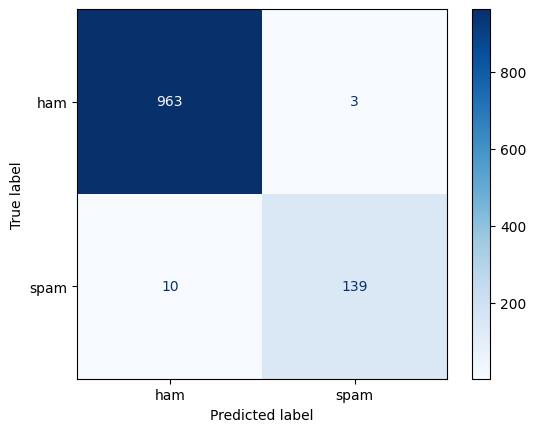

In [28]:
X_tr, X_te, y_tr, y_te = train_test_split(
    sms['text'], sms['y'], test_size=0.2, random_state=42,
    stratify=sms['y'])

word_clf = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2,
                              sublinear_tf=True)),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))])
word_clf.fit(X_tr, y_tr)
pred = word_clf.predict(X_te)
print(classification_report(y_te, pred, target_names=['ham', 'spam'],
                            digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred),
                       display_labels=['ham', 'spam']).plot(cmap='Blues')
plt.show()

### Calculations: Task 2.2 (word model)

**Split sizes.** $0.2\times5572 = 1114.4 \to$ **1,115 test messages** (966 ham + 149 spam) and 4,457 training messages (3,859 ham + 598 spam).

**Class weights** (`balanced`): 

$$c_{\text{spam}} = \frac{4457}{2\times598} = 3.73 \qquad c_{\text{ham}} = \frac{4457}{2\times3859} = 0.58$$

so a missed spam message costs about 6.5 times as much as a missed ham message during training.

**Sublinear tf example.** A word used 10 times gets $1+\ln 10 = 3.30$ instead of 10, and one used twice gets $1+\ln 2 = 1.69$.

**Confusion matrix recovered from the report** (spam recall 0.933 and precision 0.979):

| | Predicted ham | Predicted spam |
|---|---|---|
| **True ham (966)** | TN = 963 | FP = 3 |
| **True spam (149)** | FN = 10 | TP = 139 |

$$P_{\text{spam}}=\frac{139}{139+3}=0.979 \qquad R_{\text{spam}}=\frac{139}{139+10}=\frac{139}{149}=0.933 \qquad F_{1,\text{spam}}=\frac{2(0.979)(0.933)}{0.979+0.933}=0.955$$

$$P_{\text{ham}}=\frac{963}{963+10}=0.990 \qquad R_{\text{ham}}=\frac{963}{966}=0.997 \qquad F_{1,\text{ham}}=\frac{2(0.990)(0.997)}{0.990+0.997}=0.993$$

$$\text{macro-}F_1=\frac{0.993+0.955}{2}=\mathbf{0.974} \qquad \text{accuracy}=\frac{963+139}{1115}=0.988 \qquad \text{errors}=3+10=13$$

All of these match the printed report (`macro avg f1 0.974`, `accuracy 0.988`).

### Task 2.3: What did the word model learn?

**What this cell does.** Reads the learned weights $\mathbf{w}$ of the logistic regression and sorts them. A large positive weight means the n-gram pushes the message toward spam; a large negative weight pushes it toward ham. The 12 most extreme on each side are saved in `top_spam` and `top_ham`.

**Equation.** The log-odds of spam is a sum of contributions, one per n-gram:

$$z=\ln\frac{P(\text{spam})}{1-P(\text{spam})}=b+\sum_i w_i\,x_i$$

where $x_i$ is the TF-IDF value of n-gram $i$ in the message, so a high-weight word that is also frequent in the message moves $z$ the most.

In [29]:
tfv = word_clf.named_steps['tfidf']
coef = word_clf.named_steps['model'].coef_[0]
terms = tfv.get_feature_names_out()
order = np.argsort(coef)
top_spam = list(terms[order[-12:]][::-1])
top_ham = list(terms[order[:12]])
print('Most spam-like :', top_spam)
print('Most ham-like  :', top_ham)

Most spam-like : ['call', 'txt', 'free', 'text', 'reply', 'uk', 'to', 'www', 'mobile', 'claim', 'stop', 'your']
Most ham-like  : ['my', 'me', 'ok', 'that', 'it', 'but', 'll', 'gt', 'lt', 'can', 'what', 'da']


### Reading the output: Task 2.3

| Direction | Top n-grams printed | Verdict |
|---|---|---|
| Spam-like | call, txt, free, text, reply, uk, to, www, mobile, claim, stop, your | mostly sensible: calls to action, short-code replies, web and UK-number cues |
| Ham-like | my, me, ok, that, it, but, ll, gt, lt, can, what, da | personal chat words |

**Shortcut-like features.** "to" and "your" are function words; they lean spam only because spam says "to claim", "to stop" and talks to "you". **Dataset artefacts:** "gt" and "lt" are leftovers of the HTML escapes `&gt;` and `&lt;` in the ham messages, and "da" is an Indian-English chat particle. A model leaning on these would not transfer to a new message source.

**A concrete cost.** "Waiting for your call." (a ham message) scores $p=0.85$, which is a log-odds of $z=\ln\frac{0.85}{0.15}=1.74$, because "your" and "call" are both top spam features.

### Task 2.4: Character n-grams and spelling tricks

**What this cell does.**

1. Trains a second pipeline that uses **character n-grams of length 2 to 5 inside word boundaries** (`char_wb`) instead of words.
2. Stores macro-F1, spam precision, spam recall, vocabulary size and the number of errors for both models in `results`.
3. Prints the full report for the character model.
4. Scores five tricky messages with both models (two from the lab, three of my own: a disguised English spam, a Roman Urdu spam and a Roman Urdu ham as a control). A message is flagged as spam when $p\ge0.5$.

**Why characters?** Misspellings such as "FR33 pr1ze" still share fragments with "free prize", and Roman Urdu has no fixed spelling ("acha", "achha", "accha"), but overlapping fragments ("ach", "cha") still match.

In [30]:
char_clf = Pipeline([
    ('tfidf', TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5),
                              min_df=2, sublinear_tf=True)),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))])
char_clf.fit(X_tr, y_tr)

results = {}
for name, key, clf in [('word 1-2 grams', 'word', word_clf),
                       ('char 2-5 grams', 'char', char_clf)]:
    p = clf.predict(X_te)
    rep = classification_report(y_te, p, output_dict=True)
    results[key] = dict(macro_f1=f1_score(y_te, p, average='macro'),
                        prec=rep['1']['precision'], rec=rep['1']['recall'],
                        n_feat=len(clf.named_steps['tfidf'].vocabulary_),
                        n_err=int((p != y_te.values).sum()))
    print(f'{name:15s} macro-F1 {results[key]["macro_f1"]:.3f}  '
          f'features {results[key]["n_feat"]:,}')

print()
print('Character model, full report:')
print(classification_report(y_te, char_clf.predict(X_te),
                            target_names=['ham', 'spam'], digits=3))

# Robustness to spelling tricks: two from the lab, three of my own
# (disguised English spam, Roman Urdu spam, Roman Urdu ham as a control)
tricky_msgs = [
    ('W1N a FR33 pr1ze!! txt CLAIM now', 'spam'),                              # lab
    ('kal milte hain, 5 baje', 'ham'),                                          # lab
    ('C0ngrats!! U w0n Rs 25000 pr1ze. Cl@im by txt 5588 now', 'spam'),         # mine
    ('Mubarak ho! Aap ne 50000 ka inaam jeeta hai, abhi 8000 par SMS karein',
     'spam'),                                                                   # mine
    ('Yaar meeting kal subah 9 baje hai, notes bhej dena', 'ham')]              # mine
msgs = [m for m, _ in tricky_msgs]
tricky_df = pd.DataFrame({
    'message': msgs, 'expected': [e for _, e in tricky_msgs],
    'word_p_spam': word_clf.predict_proba(msgs)[:, 1].round(2),
    'char_p_spam': char_clf.predict_proba(msgs)[:, 1].round(2)})
pd.set_option('display.max_colwidth', 80)
print(tricky_df.to_string())

word 1-2 grams  macro-F1 0.974  features 12,128
char 2-5 grams  macro-F1 0.982  features 36,449

Character model, full report:
              precision    recall  f1-score   support

         ham      0.993     0.998     0.995       966
        spam      0.986     0.953     0.969       149

    accuracy                          0.992      1115
   macro avg      0.989     0.975     0.982      1115
weighted avg      0.992     0.992     0.992      1115

                                                                 message expected  word_p_spam  char_p_spam
0                                       W1N a FR33 pr1ze!! txt CLAIM now     spam         0.99         0.85
1                                                 kal milte hain, 5 baje      ham         0.19         0.12
2                 C0ngrats!! U w0n Rs 25000 pr1ze. Cl@im by txt 5588 now     spam         0.81         0.88
3  Mubarak ho! Aap ne 50000 ka inaam jeeta hai, abhi 8000 par SMS karein     spam         0.32         0.53
4     

### Calculations: Task 2.4 (character model and comparison)

**Confusion matrix recovered from the printed report** (spam recall 0.953, precision 0.986):

| | Predicted ham | Predicted spam |
|---|---|---|
| **True ham (966)** | TN = 964 | FP = 2 |
| **True spam (149)** | FN = 7 | TP = 142 |

$$P_{\text{spam}}=\frac{142}{144}=0.986 \qquad R_{\text{spam}}=\frac{142}{149}=0.953 \qquad F_{1,\text{spam}}=\frac{2(0.986)(0.953)}{0.986+0.953}=0.969$$

$$\text{macro-}F_1=\frac{0.995+0.969}{2}=\mathbf{0.982} \qquad \text{accuracy}=\frac{964+142}{1115}=0.992 \qquad \text{errors}=2+7=9$$

**Word vs character, side by side**

| Model | Features | Macro-F1 | Spam precision | Spam recall | Errors |
|---|---|---|---|---|---|
| word 1-2 grams | 12,128 | 0.974 | 0.979 | 0.933 | 13 |
| char_wb 2-5 grams | 36,449 | 0.982 | 0.986 | 0.953 | 9 |

$$\text{gain}=0.982-0.974=0.008 \;\;(\text{only } 13-9=4 \text{ messages of } 1115) \qquad \frac{36{,}449}{12{,}128}=3.0\times\text{ more features}$$

A 4-message gap on one split is too small to call a real difference on clean English SMS, so the case for characters rests on **robustness**, shown by the tricky messages:

| Message | Expected | Word p(spam) | Char p(spam) |
|---|---|---|---|
| W1N a FR33 pr1ze!! txt CLAIM now | spam | 0.99 (ok) | 0.85 (ok) |
| kal milte hain, 5 baje | ham | 0.19 (ok) | 0.12 (ok) |
| C0ngrats!! U w0n Rs 25000 pr1ze. Cl@im by txt 5588 now | spam | 0.81 (ok) | 0.88 (ok) |
| Mubarak ho! Aap ne 50000 ka inaam jeeta hai... | spam | **0.32 (missed)** | 0.53 (ok, barely) |
| Yaar meeting kal subah 9 baje hai, notes bhej dena | ham | 0.13 (ok) | 0.12 (ok) |

For the Roman Urdu spam the word model gives $z=\ln\frac{0.32}{0.68}=-0.75$ (missed) while the character model gives $z=\ln\frac{0.53}{0.47}=+0.12$, over the 0.5 line by only 0.03. Neither model was trained on Roman Urdu, so this is untrained behaviour, not evidence of real support.

### Task 2.5: Error analysis of the word model

**What this cell does.** Lists every test message the word model got wrong (probability on the wrong side of 0.5), sorted by $p(\text{spam})$, and attaches **my own category** to each one using the `ERROR_NOTES` dictionary: *model error* (the model should have got it), *label error* (the dataset label looks wrong) or *genuinely ambiguous* (a person could argue either way).

In [31]:
# My classification of every misclassified message, keyed by its row number in the data.
# category = model error | label error | genuinely ambiguous
ERROR_NOTES = {
    750:  ('label error', 'ordinary chat sentence, no commercial cue; label looks wrong'),
    2246: ('genuinely ambiguous', 'a warning ABOUT a scam that quotes the scam; reader could say ham'),
    3979: ('model error', 'brand + short code; word "ringtoneking" never seen in training'),
    1429: ('genuinely ambiguous', 'classified ad that reads like a personal message'),
    2821: ('model error', 'horoscope subscription spam; token "ROMCAPspam" is a giveaway the words hide'),
    3358: ('model error', 'missed-call scam; the only cue is the 070 number, unique numbers cannot be learned as words'),
    5449: ('genuinely ambiguous', 'joke/news subscription blurb; a person might call it ham'),
    5:    ('model error', '"FreeMsg", "std chgs", price: clear cues missed (pound sign is mojibake)'),
    2351: ('model error', 'ringtones + SMS shorthand (u, 2, Txt); p just under 0.5'),
    1268: ('model error', 'premium number and "Call me NOW"; p = 0.46, borderline'),
    5044: ('genuinely ambiguous', 'bulk recruitment message with "contact us"; label ham is debatable'),
    152:  ('model error', 'clearly ham; "ur" leans spam'),
    573:  ('model error', 'shortcut: "your" + "call" are top spam features'),
}

p_te = word_clf.predict_proba(X_te)[:, 1]
err = pd.DataFrame({'text': X_te, 'true': y_te, 'p_spam': p_te})
err = err[(err.p_spam >= 0.5) != (err.true == 1)].copy()
err['category'] = [ERROR_NOTES.get(i, ('unclassified', ''))[0] for i in err.index]
err['why'] = [ERROR_NOTES.get(i, ('', ''))[1] for i in err.index]
pd.set_option('display.max_colwidth', 90)
print(err.sort_values('p_spam')[['text', 'true', 'p_spam', 'category']].to_string())
print()
print(err['category'].value_counts().to_string())

                                                                                                                                                                                       text  true    p_spam             category
750                                                                                  Do you realize that in about 40 years, we'll have thousands of old ladies running around with tattoos?     1  0.087598          label error
2246  Hi ya babe x u 4goten bout me?' scammers getting smart..Though this is a regular vodafone no, if you respond you get further prem rate msg/subscription. Other nos used also. Beware!     1  0.144048  genuinely ambiguous
3979                                                                                                                                                                     ringtoneking 84484     1  0.192426          model error
1429                                                                                                

### Calculations: Task 2.5

**Error count.** Messages with true label spam and $p<0.5$ are false negatives; true ham with $p\ge0.5$ are false positives:

$$\underbrace{10}_{\text{FN, p from 0.09 to 0.46}} + \underbrace{3}_{\text{FP, p = 0.62, 0.64, 0.85}} = 13 \;\;\text{errors, matching the confusion matrix in Task 2.2}$$

**My classification of the 13 errors**

| Category | Count | Share of errors |
|---|---|---|
| model error | 8 | $8/13 = 61.5\%$ |
| genuinely ambiguous | 4 | $4/13 = 30.8\%$ |
| label error | 1 | $1/13 = 7.7\%$ |

**Ceiling effect.** If I set aside the 5 errors that are label problems or ambiguous, the 8 true model errors leave accuracy at $\frac{1115-8}{1115}=0.993$, against 0.988 measured. Beyond that point a higher score on this dataset mostly means fitting arguable labels.

**Fixable causes of the model errors:** SMS shorthand ("u", "2", "Txt"), short codes and unique phone numbers (a number like 07090201529 appears only once, so it cannot be learned as a word), unseen glued tokens ("ringtoneking", "ROMCAPspam"), and the "your call" shortcut. The character model makes 9 errors instead of 13 on the same test set.

### Write it: Part 2 (summary of results and judgement)

**What this cell does.** It builds the written answer for Part 2 from the variables above (`results`, `err`, `tricky_df`, `top_spam`, `top_ham`), so every number in the text is the number computed in this run: scores for both models, the verdict on the top features, the table of all 13 errors with my categories, and the tricky-message table. The hand calculations behind those numbers are in the Calculations blocks above.

In [32]:
r_w, r_c = results['word'], results['char']
gap = abs(r_w['n_err'] - r_c['n_err'])
better = 'character' if r_c['macro_f1'] > r_w['macro_f1'] else 'word'
cats = err['category'].value_counts().to_dict()

err_rows = '\n'.join(
    f"| {str(t)[:55].replace('|', '/')}... | {int(tr)} | {pp:.2f} | {c} | {w} |"
    for t, tr, pp, c, w in err.sort_values('p_spam')[
        ['text', 'true', 'p_spam', 'category', 'why']].itertuples(index=False))

trick_rows = '\n'.join(
    f"| {m[:60]} | {e} | {a:.2f} {'OK' if (a >= .5) == (e == 'spam') else 'MISSED'} "
    f"| {b:.2f} {'OK' if (b >= .5) == (e == 'spam') else 'MISSED'} |"
    for m, e, a, b in tricky_df[['message', 'expected', 'word_p_spam',
                                 'char_p_spam']].itertuples(index=False))

show(f"""


**Scores on the {len(y_te):,}-message test split** (spam is {y_te.mean():.1%}, so "always ham" already scores {1 - y_te.mean():.1%} accuracy and accuracy is not the right metric).

| Model | Features | Macro-F1 | Spam precision | Spam recall | Errors |
|---|---|---|---|---|---|
| word 1-2 grams | {r_w['n_feat']:,} | {r_w['macro_f1']:.3f} | {r_w['prec']:.3f} | {r_w['rec']:.3f} | {r_w['n_err']} |
| char_wb 2-5 grams | {r_c['n_feat']:,} | {r_c['macro_f1']:.3f} | {r_c['prec']:.3f} | {r_c['rec']:.3f} | {r_c['n_err']} |

The {better} model is ahead by {abs(r_c['macro_f1'] - r_w['macro_f1']):.3f} macro-F1, which is only {gap} messages out of {len(y_te):,}. On one split that is too small to call a real difference on clean English SMS, so the case for characters rests on robustness (below), not on this gap. The cost is a vocabulary about {r_c['n_feat'] / r_w['n_feat']:.1f} times larger and weights that are fragments, not words.

**Top features (word model).**
Spam-like: {', '.join(top_spam)}.
Ham-like: {', '.join(top_ham)}.

- *Sensible:* claim, free, txt, text, reply, stop, mobile, www, uk, call. This is the classic SMS-spam vocabulary (calls to action and short-code replies).
- *Shortcut-like:* "to" and "your" are function words. They lean spam only because spam says "to claim", "to stop" and speaks to "you". The harm is real: "Waiting for your call." (a ham message) gets p(spam) = 0.85 because "your" and "call" are both top spam features.
- *Dataset artefacts, not language:* "gt" and "lt" (leftovers of the HTML escapes &gt; and &lt; in the ham messages) and "da" (an Indian-English chat particle). The model would not carry these to a new message source.

**Error analysis ({len(err)} misclassified: {cats}).** The word model makes {int((err.true == 1).sum())} false negatives and {int((err.true == 0).sum())} false positives.

| Message | True | p(spam) | My category | Why |
|---|---|---|---|---|
{err_rows}

Most errors are the model's, and they are fixable (SMS shorthand, short codes, unseen glued tokens, shortcuts on "your call"). A few are labels a human would argue about, which puts a ceiling on any score on this dataset.

**Tricky messages (two from the lab, three of mine; threshold 0.5).**

| Message | Expected | Word model p(spam) | Char model p(spam) |
|---|---|---|---|
{trick_rows}

Character n-grams share pieces such as "pr", "ze" and "claim" across misspellings, so a disguised "pr1ze" still looks close to "prize". Word features see an unseen token and ignore it. Roman Urdu has no fixed spelling, so characters help there too, but neither model was trained on Roman Urdu, so I treat the Roman Urdu scores as untrained behaviour, not as evidence.
""")




**Scores on the 1,115-message test split** (spam is 13.4%, so "always ham" already scores 86.6% accuracy and accuracy is not the right metric).

| Model | Features | Macro-F1 | Spam precision | Spam recall | Errors |
|---|---|---|---|---|---|
| word 1-2 grams | 12,128 | 0.974 | 0.979 | 0.933 | 13 |
| char_wb 2-5 grams | 36,449 | 0.982 | 0.986 | 0.953 | 9 |

The character model is ahead by 0.008 macro-F1, which is only 4 messages out of 1,115. On one split that is too small to call a real difference on clean English SMS, so the case for characters rests on robustness (below), not on this gap. The cost is a vocabulary about 3.0 times larger and weights that are fragments, not words.

**Top features (word model).**
Spam-like: call, txt, free, text, reply, uk, to, www, mobile, claim, stop, your.
Ham-like: my, me, ok, that, it, but, ll, gt, lt, can, what, da.

- *Sensible:* claim, free, txt, text, reply, stop, mobile, www, uk, call. This is the classic SMS-spam vocabulary (calls to action and short-code replies).
- *Shortcut-like:* "to" and "your" are function words. They lean spam only because spam says "to claim", "to stop" and speaks to "you". The harm is real: "Waiting for your call." (a ham message) gets p(spam) = 0.85 because "your" and "call" are both top spam features.
- *Dataset artefacts, not language:* "gt" and "lt" (leftovers of the HTML escapes &gt; and &lt; in the ham messages) and "da" (an Indian-English chat particle). The model would not carry these to a new message source.

**Error analysis (13 misclassified: {'model error': 8, 'genuinely ambiguous': 4, 'label error': 1}).** The word model makes 10 false negatives and 3 false positives.

| Message | True | p(spam) | My category | Why |
|---|---|---|---|---|
| Do you realize that in about 40 years, we'll have thous... | 1 | 0.09 | label error | ordinary chat sentence, no commercial cue; label looks wrong |
| Hi ya babe x u 4goten bout me?' scammers getting smart.... | 1 | 0.14 | genuinely ambiguous | a warning ABOUT a scam that quotes the scam; reader could say ham |
| ringtoneking 84484... | 1 | 0.19 | model error | brand + short code; word "ringtoneking" never seen in training |
| For sale - arsenal dartboard. Good condition but no dou... | 1 | 0.21 | genuinely ambiguous | classified ad that reads like a personal message |
| ROMCAPspam Everyone around should be responding well to... | 1 | 0.25 | model error | horoscope subscription spam; token "ROMCAPspam" is a giveaway the words hide |
| Sorry I missed your call let's talk when you have the t... | 1 | 0.28 | model error | missed-call scam; the only cue is the 070 number, unique numbers cannot be learned as words |
| Latest News! Police station toilet stolen, cops have no... | 1 | 0.31 | genuinely ambiguous | joke/news subscription blurb; a person might call it ham |
| FreeMsg Hey there darling it's been 3 week's now and no... | 1 | 0.41 | model error | "FreeMsg", "std chgs", price: clear cues missed (pound sign is mojibake) |
| Download as many ringtones as u like no restrictions, 1... | 1 | 0.42 | model error | ringtones + SMS shorthand (u, 2, Txt); p just under 0.5 |
| Can U get 2 phone NOW? I wanna chat 2 set up meet Call ... | 1 | 0.46 | model error | premium number and "Call me NOW"; p = 0.46, borderline |
| We have sent JD for Customer Service cum Accounts Execu... | 0 | 0.62 | genuinely ambiguous | bulk recruitment message with "contact us"; label ham is debatable |
| Ok... Ur typical reply...... | 0 | 0.64 | model error | clearly ham; "ur" leans spam |
| Waiting for your call.... | 0 | 0.85 | model error | shortcut: "your" + "call" are top spam features |

Most errors are the model's, and they are fixable (SMS shorthand, short codes, unseen glued tokens, shortcuts on "your call"). A few are labels a human would argue about, which puts a ceiling on any score on this dataset.

**Tricky messages (two from the lab, three of mine; threshold 0.5).**

| Message | Expected | Word model p(spam) | Char model p(spam) |
|---|---|---|---|
| W1N a FR33 pr1ze!! txt CLAIM now | spam | 0.99 OK | 0.85 OK |
| kal milte hain, 5 baje | ham | 0.19 OK | 0.12 OK |
| C0ngrats!! U w0n Rs 25000 pr1ze. Cl@im by txt 5588 now | spam | 0.81 OK | 0.88 OK |
| Mubarak ho! Aap ne 50000 ka inaam jeeta hai, abhi 8000 par S | spam | 0.32 MISSED | 0.53 OK |
| Yaar meeting kal subah 9 baje hai, notes bhej dena | ham | 0.13 OK | 0.12 OK |

Character n-grams share pieces such as "pr", "ze" and "claim" across misspellings, so a disguised "pr1ze" still looks close to "prize". Word features see an unseen token and ignore it. Roman Urdu has no fixed spelling, so characters help there too, but neither model was trained on Roman Urdu, so I treat the Roman Urdu scores as untrained behaviour, not as evidence.


## Part 3: Named Entity Recognition, Measured (20 min)

**Goal.** Extract the people, organisations, places, dates and amounts a database could store, and *measure* how well it works. Without a measurement, "it seems to extract names" is not an engineering result.

**NER is token classification.** Each token gets a BIO tag: `B-X` (begin entity of type X), `I-X` (inside the same entity) or `O` (outside). For example "Engro Fertilizers billed PKR 45,000" becomes `B-ORG I-ORG O B-MONEY I-MONEY`.

### Task 3.1: spaCy out of the box

**What this cell does.** Runs the pre-trained `en_core_web_sm` model on six Pakistani sentences and prints each entity with its label. The model was trained mostly on US and European news, so local names, formats and currency are out of distribution.

In [33]:
sentences = [
    'Dr. Ayesha Khan at PIMS Islamabad reviewed it on 12 September 2026.',
    'The invoice from Engro Fertilizers for PKR 45,000 is due on 30/09/2026.',
    'Farmer Muhammad Aslam from Multan reported leaf rust in his wheat crop.',
    'Call Jazz support at 0300-1234567 or email help@jazz.com.pk.',
    'Meezan Bank approved a loan of Rs. 250,000 for Bilal Ahmed.',
    'The consignment left Karachi Port on Monday for Lahore.']
for s in sentences:
    doc = nlp(s)
    print([(e.text, e.label_) for e in doc.ents])

[('Ayesha Khan', 'PERSON'), ('PIMS Islamabad', 'LOC'), ('12 September 2026', 'DATE')]
[('Engro Fertilizers', 'PERSON'), ('30/09/2026', 'GPE')]
[('Farmer Muhammad Aslam', 'PERSON'), ('Multan', 'GPE')]
[('0300-1234567', 'DATE')]
[('Meezan Bank', 'ORG'), ('250,000', 'CARDINAL'), ('Bilal Ahmed', 'PERSON')]
[('Karachi Port', 'FAC'), ('Monday', 'DATE'), ('Lahore', 'GPE')]


### Reading the output: Task 3.1

| Sentence | What spaCy said | What it should be |
|---|---|---|
| 1 | `PIMS Islamabad` as one **LOC** | `PIMS` = ORG and `Islamabad` = GPE (two entities) |
| 2 | `Engro Fertilizers` = **PERSON**; `30/09/2026` = **GPE**; `PKR 45,000` not found | ORG; DATE; MONEY |
| 3 | `Farmer Muhammad Aslam` = PERSON (title included) | `Muhammad Aslam` |
| 4 | `0300-1234567` = **DATE**; `Jazz` not found | a phone number (regex, not NER); ORG |
| 5 | `250,000` = **CARDINAL** | `Rs. 250,000` = MONEY |
| 6 | Karachi Port FAC, Monday DATE, Lahore GPE | all correct |

These are the failures the lecture (slide 20) predicts: a company read as a person, a date read as a place, and a phone number read as a date.

### Task 3.2: Score against a gold set

**What this cell does.** Writes the **gold annotations** (what a careful human would mark) for the six sentences, defines `score_ner`, and scores spaCy. An entity counts as correct only if **both its exact text and its label** match the gold entity.

**Equations**

$$P=\frac{TP}{TP+FP}\qquad R=\frac{TP}{TP+FN}\qquad F_1=\frac{2PR}{P+R}$$

where TP = predicted entities that are in the gold set, FP = predicted but not gold, FN = gold but not predicted.

In [34]:
# Gold annotations: what a careful human would mark (text, label)
gold = [
    {('Ayesha Khan', 'PERSON'), ('PIMS', 'ORG'), ('Islamabad', 'GPE'),
     ('12 September 2026', 'DATE')},
    {('Engro Fertilizers', 'ORG'), ('PKR 45,000', 'MONEY'),
     ('30/09/2026', 'DATE')},
    {('Muhammad Aslam', 'PERSON'), ('Multan', 'GPE')},
    {('Jazz', 'ORG')},
    {('Meezan Bank', 'ORG'), ('Rs. 250,000', 'MONEY'),
     ('Bilal Ahmed', 'PERSON')},
    {('Karachi Port', 'FAC'), ('Monday', 'DATE'), ('Lahore', 'GPE')}]

def score_ner(model, sents, golds):
    """Entity-level scores: an entity is correct only if exact text AND label match."""
    tp = fp = fn = 0
    fp_list, fn_list = [], []
    for s, g in zip(sents, golds):
        pred = {(e.text, e.label_) for e in model(s).ents}
        tp += len(pred & g)
        fp += len(pred - g)
        fn += len(g - pred)
        fp_list += sorted(pred - g)
        fn_list += sorted(g - pred)
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * p * r / (p + r) if p + r else 0.0
    return {'precision': round(p, 3), 'recall': round(r, 3), 'f1': round(f1, 3),
            'tp': tp, 'fp': fp, 'fn': fn, 'fp_list': fp_list, 'fn_list': fn_list}

def ner_scores(nlp_model):
    s = score_ner(nlp_model, sentences, gold)
    return {k: s[k] for k in ('precision', 'recall', 'f1')}

LAB_BEFORE = ner_scores(nlp)
print('spaCy out of the box:', LAB_BEFORE)
print('gold entities:', sum(len(g) for g in gold))

spaCy out of the box: {'precision': 0.571, 'recall': 0.5, 'f1': 0.533}
gold entities: 16


### Calculations: Task 3.2 (spaCy out of the box)

| Sentence | Gold | Predicted correctly (TP) | Wrong (FP) | Missed (FN) |
|---|---|---|---|---|
| 1 | 4 | 2 (Ayesha Khan, 12 September 2026) | 1 (PIMS Islamabad) | 2 (PIMS, Islamabad) |
| 2 | 3 | 0 | 2 (Engro as PERSON, date as GPE) | 3 |
| 3 | 2 | 1 (Multan) | 1 (Farmer Muhammad Aslam) | 1 (Muhammad Aslam) |
| 4 | 1 | 0 | 1 (phone as DATE) | 1 (Jazz) |
| 5 | 3 | 2 (Meezan Bank, Bilal Ahmed) | 1 (250,000 CARDINAL) | 1 (Rs. 250,000) |
| 6 | 3 | 3 | 0 | 0 |
| **Total** | **16** | **8** | **6** | **8** |

$$P=\frac{8}{8+6}=\frac{8}{14}=0.571 \qquad R=\frac{8}{8+8}=\frac{8}{16}=0.500 \qquad F_1=\frac{2(0.571)(0.500)}{0.571+0.500}=0.533$$

The printed result is `{'precision': 0.571, 'recall': 0.5, 'f1': 0.533}`, identical to the lecture value.

### Task 3.3: Add rules before the statistical model

**What this cell does.** Builds a **fresh** spaCy pipeline with an `entity_ruler` placed *before* the statistical `ner`, loaded with the lab's seven patterns (one token pattern for money such as `PKR` / `Rs.` followed by a number, four organisations, one facility and a `dd/mm/yyyy` regex for dates). Because the pipeline is rebuilt each time, running the cell twice cannot raise "entity_ruler already exists". It then re-scores with the same gold set.

**Why before `ner`?** Entities set by the ruler are respected by the statistical model, so a rule always wins for the cases it covers, while everything else still goes to the model.

In [35]:
def build_lab_nlp():
    """Fresh spaCy + the lab's seven entity-ruler patterns (safe to re-run)."""
    m = spacy.load('en_core_web_sm')
    ruler = m.add_pipe('entity_ruler', before='ner')
    ruler.add_patterns([
        {'label': 'MONEY', 'pattern': [{'LOWER': {'IN': ['pkr', 'rs', 'rs.']}},
                                       {'IS_PUNCT': True, 'OP': '?'},
                                       {'LIKE_NUM': True}]},
        {'label': 'ORG', 'pattern': 'Engro Fertilizers'},
        {'label': 'ORG', 'pattern': 'Meezan Bank'},
        {'label': 'ORG', 'pattern': 'PIMS'},
        {'label': 'ORG', 'pattern': 'Jazz'},
        {'label': 'FAC', 'pattern': 'Karachi Port'},
        {'label': 'DATE',
         'pattern': [{'TEXT': {'REGEX': r'^\d{1,2}/\d{1,2}/\d{4}$'}}]},
    ])
    return m

nlp_lab = build_lab_nlp()
LAB_AFTER = ner_scores(nlp_lab)
print('spaCy + entity ruler:', LAB_AFTER)
print('before -> after F1: %.3f -> %.3f   (lecture: 0.533 -> 0.875)'
      % (LAB_BEFORE['f1'], LAB_AFTER['f1']))

spaCy + entity ruler: {'precision': 0.875, 'recall': 0.875, 'f1': 0.875}
before -> after F1: 0.533 -> 0.875   (lecture: 0.533 -> 0.875)


### Calculations: Task 3.3 (with the entity ruler)

The printed score is $P=R=0.875$. With 16 gold entities that means

$$TP=14,\quad FP=2,\quad FN=2 \qquad\Rightarrow\qquad P=\frac{14}{16}=0.875,\quad R=\frac{14}{16}=0.875,\quad F_1=\frac{2(0.875)(0.875)}{0.875+0.875}=\mathbf{0.875}$$

**Improvement:** $F_1$ rose from $0.533$ to $0.875$, a gain of $+0.342$ (a $64\%$ relative increase), and the number of exact matches went from 8 to 14. This reproduces the lecture's $0.533 \to 0.875$ (`before -> after F1: 0.533 -> 0.875`).

**What is left:** two predicted entities are still wrong and two gold entities are still missed. Seven patterns cannot fix everything, for example a title absorbed into a person name ("Farmer Muhammad Aslam"), which is why Task 3.4 adds a small title-trimming step.

### Task 3.4: The same experiment on my domain (brain-tumour MRI reports)

**What this cell does.**

1. Defines **10 sentences from my domain** (hospital names, doctors, patients, cities, dates, rupee amounts) and annotates them as `(text, label)` sets, exactly like the lab's gold list. All names, amounts and dates are invented.
2. **Sentences 1-5 are the rule-writing set** and **sentences 6-10 are held out**: no rule was written from them, so their score is an honest estimate.
3. Registers a `strip_titles` component that removes a leading title ("Dr.", "Patient", "Farmer") from `PERSON` spans.
4. Builds a domain pipeline: money pattern, `dd/mm/yyyy` date pattern, the organisation `PIMS`, one generic pattern for "<Capitalised words> Hospital / Society / Centre / Clinic / Institute / Bank", and the four cities from sentences 1-5.
5. Scores baseline spaCy and the domain pipeline on both sets.

**Why hold out sentences?** A rule written from a sentence always works on that sentence, so scoring on the same sentences overstates the result.

In [36]:
from spacy.language import Language
from spacy.tokens import Span

DOMAIN_SENTS = [
    # ---- 1-5: rules are written from these ----
    'Dr. Sana Malik at Shifa International Hospital in Islamabad reviewed the MRI on 14 October 2026.',
    'The MRI at Aga Khan University Hospital cost PKR 38,000 for Usman Tariq.',
    'Patient Imran Qureshi from Rawalpindi was referred to PIMS on 03/11/2026.',
    'Dr. Hira Siddiqui of Mayo Hospital Lahore booked a biopsy for Rs. 120,000 on 22/11/2026.',
    'The Pakistan Brain Tumour Society paid Rs. 15,000 for the scan of Ali Raza in Karachi.',
    # ---- 6-10: HELD OUT, never used to write a rule ----
    'Dr. Bilal Chaudhry at Lahore General Hospital ordered an MRI on 05/12/2026.',
    'Farah Naveed paid PKR 52,500 at Shaukat Khanum Hospital in Lahore.',
    'The scan of Zainab Ahmed in Peshawar is booked for 9 January 2027.',
    'Dr. Kamran Yousaf from Nishtar Hospital in Multan quoted Rs. 80,000 for the surgery.',
    'Capital MRI Centre billed Hassan Raza PKR 24,000 on 17/12/2026.']

DOMAIN_GOLD = [
    {('Sana Malik', 'PERSON'), ('Shifa International Hospital', 'ORG'),
     ('Islamabad', 'GPE'), ('14 October 2026', 'DATE')},
    {('Aga Khan University Hospital', 'ORG'), ('PKR 38,000', 'MONEY'),
     ('Usman Tariq', 'PERSON')},
    {('Imran Qureshi', 'PERSON'), ('Rawalpindi', 'GPE'), ('PIMS', 'ORG'),
     ('03/11/2026', 'DATE')},
    {('Hira Siddiqui', 'PERSON'), ('Mayo Hospital', 'ORG'), ('Lahore', 'GPE'),
     ('Rs. 120,000', 'MONEY'), ('22/11/2026', 'DATE')},
    {('Pakistan Brain Tumour Society', 'ORG'), ('Rs. 15,000', 'MONEY'),
     ('Ali Raza', 'PERSON'), ('Karachi', 'GPE')},
    # held out
    {('Bilal Chaudhry', 'PERSON'), ('Lahore General Hospital', 'ORG'),
     ('05/12/2026', 'DATE')},
    {('Farah Naveed', 'PERSON'), ('PKR 52,500', 'MONEY'),
     ('Shaukat Khanum Hospital', 'ORG'), ('Lahore', 'GPE')},
    {('Zainab Ahmed', 'PERSON'), ('Peshawar', 'GPE'), ('9 January 2027', 'DATE')},
    {('Kamran Yousaf', 'PERSON'), ('Nishtar Hospital', 'ORG'), ('Multan', 'GPE'),
     ('Rs. 80,000', 'MONEY')},
    {('Capital MRI Centre', 'ORG'), ('Hassan Raza', 'PERSON'),
     ('PKR 24,000', 'MONEY'), ('17/12/2026', 'DATE')}]

RULE_SENTS, RULE_GOLD = DOMAIN_SENTS[:5], DOMAIN_GOLD[:5]
HELD_SENTS, HELD_GOLD = DOMAIN_SENTS[5:], DOMAIN_GOLD[5:]

TITLES = {'dr', 'mr', 'mrs', 'ms', 'prof', 'patient', 'farmer'}

@Language.component('strip_titles')
def strip_titles(doc):
    """Trim a leading title word ('Patient', 'Dr.') off PERSON entities."""
    ents = []
    for ent in doc.ents:
        if ent.label_ == 'PERSON' and len(ent) > 1 and ent[0].lower_.rstrip('.') in TITLES:
            ents.append(Span(doc, ent.start + 1, ent.end, label='PERSON'))
        else:
            ents.append(ent)
    doc.ents = ents
    return doc

HOSPITAL_SUFFIX = ['hospital', 'society', 'centre', 'center', 'clinic',
                   'institute', 'bank']
DOMAIN_RULES = [
    {'label': 'MONEY', 'pattern': [{'LOWER': {'IN': ['pkr', 'rs', 'rs.']}},
                                   {'IS_PUNCT': True, 'OP': '?'},
                                   {'LIKE_NUM': True}]},
    {'label': 'DATE',
     'pattern': [{'TEXT': {'REGEX': r'^\d{1,2}/\d{1,2}/\d{4}$'}}]},
    {'label': 'ORG', 'pattern': 'PIMS'},
    # generic "<Capitalised words> Hospital / Society / Centre ..." (not starting with "The"/"Dr.")
    {'label': 'ORG', 'pattern': [
        {'IS_TITLE': True, 'LOWER': {'NOT_IN': ['the', 'dr.']}},
        {'IS_TITLE': True, 'OP': '*'},
        {'LOWER': {'IN': HOSPITAL_SUFFIX}}]},
] + [{'label': 'GPE', 'pattern': c}
     for c in ['Islamabad', 'Rawalpindi', 'Lahore', 'Karachi']]

def build_domain_nlp():
    """Fresh spaCy + domain entity ruler + title trimming (safe to re-run)."""
    m = spacy.load('en_core_web_sm')
    m.add_pipe('entity_ruler', before='ner').add_patterns(DOMAIN_RULES)
    m.add_pipe('strip_titles', after='ner')
    return m

nlp_dom = build_domain_nlp()

rows = []
for name, sents, golds in [('rule-writing set (1-5)', RULE_SENTS, RULE_GOLD),
                           ('HELD-OUT set (6-10)', HELD_SENTS, HELD_GOLD)]:
    b = score_ner(nlp, sents, golds)
    a = score_ner(nlp_dom, sents, golds)
    rows.append((name, sum(len(g) for g in golds), b, a))
    print(f'{name:24s} gold={sum(len(g) for g in golds):2d}   '
          f'before P/R/F1 {b["precision"]}/{b["recall"]}/{b["f1"]}   '
          f'after P/R/F1 {a["precision"]}/{a["recall"]}/{a["f1"]}')

DOM_RULE_B, DOM_RULE_A = rows[0][2], rows[0][3]
DOM_HELD_B, DOM_HELD_A = rows[1][2], rows[1][3]

print('\nHeld-out, remaining errors AFTER rules')
print('  predicted but not in gold:', DOM_HELD_A['fp_list'])
print('  in gold but missed       :', DOM_HELD_A['fn_list'])
print('\nHeld-out, what spaCy alone said (before rules)')
for s in HELD_SENTS:
    print('  ', [(e.text, e.label_) for e in nlp(s).ents])

rule-writing set (1-5)   gold=20   before P/R/F1 0.625/0.5/0.556   after P/R/F1 1.0/1.0/1.0
HELD-OUT set (6-10)      gold=18   before P/R/F1 0.722/0.722/0.722   after P/R/F1 1.0/1.0/1.0

Held-out, remaining errors AFTER rules
  predicted but not in gold: []
  in gold but missed       : []

Held-out, what spaCy alone said (before rules)
   [('Bilal Chaudhry', 'PERSON'), ('Lahore General Hospital', 'ORG'), ('05/12/2026', 'ORG')]
   [('Farah Naveed', 'PERSON'), ('PKR 52,500', 'EVENT'), ('Shaukat Khanum Hospital', 'ORG'), ('Lahore', 'GPE')]
   [('Zainab Ahmed', 'PERSON'), ('Peshawar', 'GPE'), ('9 January 2027', 'DATE')]
   [('Kamran Yousaf', 'PERSON'), ('Nishtar Hospital', 'ORG'), ('Multan', 'GPE'), ('80,000', 'CARDINAL')]
   [('Capital MRI Centre', 'ORG'), ('Hassan Raza PKR', 'PERSON'), ('24,000', 'CARDINAL'), ('17/12/2026', 'DATE')]


### Calculations: Task 3.4 (domain gold set)

**Gold entity counts:** sentences 1-5 have $4+3+4+5+4=20$ entities; sentences 6-10 have $3+4+3+4+4=18$; total 38.

| Set | Pipeline | TP | FP | FN | Precision | Recall | $F_1$ |
|---|---|---|---|---|---|---|---|
| 1-5 (rule-writing) | spaCy alone | 10 | 6 | 10 | $10/16=0.625$ | $10/20=0.500$ | $0.556$ |
| 1-5 (rule-writing) | + domain rules | 20 | 0 | 0 | $1.000$ | $1.000$ | $1.000$ |
| 6-10 (held out) | spaCy alone | 13 | 5 | 5 | $13/18=0.722$ | $13/18=0.722$ | $0.722$ |
| 6-10 (held out) | + domain rules | 18 | 0 | 0 | $1.000$ | $1.000$ | $1.000$ |

$$F_{1,\text{rule set}}=\frac{2(0.625)(0.500)}{0.625+0.500}=0.556 \qquad F_{1,\text{held-out}}=\frac{2(0.722)(0.722)}{0.722+0.722}=0.722$$

**Exactly which held-out errors the rules removed.** spaCy alone made these five wrong predictions, each paired with a missed gold entity:

| spaCy alone said | Gold says |
|---|---|
| `05/12/2026` as **ORG** | `05/12/2026` DATE |
| `PKR 52,500` as **EVENT** | `PKR 52,500` MONEY |
| `80,000` as **CARDINAL** | `Rs. 80,000` MONEY |
| `Hassan Raza PKR` as **PERSON** | `Hassan Raza` PERSON (and `PKR 24,000` MONEY) |
| `24,000` as **CARDINAL** | `PKR 24,000` MONEY |

All five are **money amounts and dd/mm/yyyy dates**, so the two format rules did all of the work on the held-out set. The other $18-5=13$ entities (all four organisations, Peshawar, Multan, Lahore, "9 January 2027" and four of the five people) were already correct before any rule.

**Caution.** One wrong entity moves $F_1$ by about $1/18=0.056$, and the held-out sentences share their formats (PKR / Rs. / `dd/mm/yyyy`) with the first five. So the perfect score shows that **format rules transfer to new sentences of the same style**; it does not show that my hospital pattern or city list would hold up on unseen names, because spaCy already handled those.

### Write it: Part 3 (summary of results and judgement)

**What this cell does.** Builds the written answer for Part 3 from the stored scores: the provided-sentence table, my domain table, the errors that remain, and a breakdown of what the rules actually changed on the held-out sentences. This version of the cell reports what changed *relative to spaCy alone*, so it does not credit the rules for entities spaCy already got right.

In [37]:
b, a = DOM_HELD_B, DOM_HELD_A
r_b, r_a = DOM_RULE_B, DOM_RULE_A
n_held = sum(len(g) for g in HELD_GOLD)
n_rule = sum(len(g) for g in RULE_GOLD)
fmt = lambda xs: '; '.join(f'{t} [{l}]' for t, l in xs) or 'none'

held_gold_all = set().union(*HELD_GOLD)
missed = set(a['fn_list'])
def split(pred):
    items = sorted(t for t, l in held_gold_all if pred(t, l))
    return [t for t in items if (t, next(l for tt, l in held_gold_all if tt == t)) not in missed], \
           [t for t in items if (t, next(l for tt, l in held_gold_all if tt == t)) in missed], items
orgs_found, orgs_missed, _ = split(lambda t, l: l == 'ORG')
fmt_found, fmt_missed, fmt_gold = split(lambda t, l: l == 'MONEY' or (l == 'DATE' and '/' in t))
ppl_found, ppl_missed, ppl_gold = split(lambda t, l: l == 'PERSON')
city_missed = sorted(t for t, l in held_gold_all if l == 'GPE' and (t, l) in missed)
missed_before = set(b['fn_list'])
already_ok = sorted(t for t, l in held_gold_all if (t, l) not in missed_before)
fixed_ents = sorted((t, l) for t, l in held_gold_all if (t, l) in missed_before and (t, l) not in missed)
fixed_labels = sorted({l for _, l in fixed_ents})
ppl_bad = '; '.join([f'{t} [{l}]' for t, l in a['fp_list'] if l == 'PERSON'] + [f'missed {t}' for t in ppl_missed])

show(f"""

**Provided sentences** (6 sentences, {sum(len(g) for g in gold)} gold entities, exact text AND label must match)

| Pipeline | Precision | Recall | F1 |
|---|---|---|---|
| spaCy out of the box | {LAB_BEFORE['precision']} | {LAB_BEFORE['recall']} | {LAB_BEFORE['f1']} |
| + 7 entity-ruler patterns | {LAB_AFTER['precision']} | {LAB_AFTER['recall']} | {LAB_AFTER['f1']} |

**My domain (brain-tumour MRI reports, 10 sentences)**

| Set | Gold entities | F1 before rules | F1 after rules |
|---|---|---|---|
| Sentences 1-5 (rules written from these, so optimistic) | {n_rule} | {r_b['f1']} | {r_a['f1']} |
| **Sentences 6-10 (held out, honest number)** | {n_held} | **{b['f1']}** | **{a['f1']}** |

On the held-out set precision went {b['precision']} -> {a['precision']} and recall {b['recall']} -> {a['recall']}. The held-out score is {'not lower than' if a['f1'] >= r_a['f1'] else 'lower than'} the rule-writing score, so on this data I did not see the optimism gap the lab warns about. Treat that with caution: with {n_held} entities one wrong entity moves F1 by about {1 / n_held:.2f}, and my held-out sentences share their formats (PKR / Rs. / dd/mm/yyyy) with the first five, so this shows that format rules carry over to new sentences of the same style, not that they carry over to unseen styles.

**Errors that remain on the held-out set after the rules**

- Predicted but wrong: {fmt(a['fp_list'])}
- Missed: {fmt(a['fn_list'])}

**What the rules did on the held-out sentences, compared with spaCy alone.**

- *Already correct before any rule:* {len(already_ok)} of {n_held} ({', '.join(already_ok) or 'none'}). The rules could not improve these, so this set barely tests my hospital-suffix pattern or my city list.
- *Fixed by the rules:* {len(fixed_ents)} of {n_held}: {', '.join(t for t, _ in fixed_ents) or 'none'}. Their labels: {', '.join(fixed_labels) or 'none'}.
- *Still wrong or missed after the rules:* {len(a['fp_list'])} wrong, {len(a['fn_list'])} missed.
- *People:* {len(ppl_found)} of {len(ppl_gold)} person entities matched exactly after the rules; wrong or missed person spans: {ppl_bad or 'none'}.
- *Cities:* only the four I saw in sentences 1-5 are in my list, so a city outside it depends on spaCy alone (missed here: {', '.join(city_missed) or 'none'}).

**How I would fix what is left.** The right tool depends on the kind of error:

- *Closed vocabularies* (hospital names, cities, a society's name) are a **rules / gazetteer** problem. A suffix pattern ("... Hospital") only covers names of that shape, and a city is missed until it is added to the list. spaCy already handled every organisation in my held-out set, so I cannot yet show that my pattern adds value; I need held-out sentences with hospital names that spaCy gets wrong.
- *Formats* (dd/mm/yyyy, PKR / Rs. amounts) are a **regex** problem: they are rigid, so a pattern written from a few examples carries over to new sentences. Written dates ("9 January 2027") are left to spaCy.
- *Open-class person names and borderline org-versus-person cases* (a hospital named after a person, such as "Shaukat Khanum", can look like a person) cannot be listed. These need **a model trained on my own annotated data**. With {n_rule + n_held} gold entities there is far too little to train one, so for now I use rules plus title trimming and I would annotate a few hundred real report sentences before fine-tuning the NER.
""")



**Provided sentences** (6 sentences, 16 gold entities, exact text AND label must match)

| Pipeline | Precision | Recall | F1 |
|---|---|---|---|
| spaCy out of the box | 0.571 | 0.5 | 0.533 |
| + 7 entity-ruler patterns | 0.875 | 0.875 | 0.875 |

**My domain (brain-tumour MRI reports, 10 sentences)**

| Set | Gold entities | F1 before rules | F1 after rules |
|---|---|---|---|
| Sentences 1-5 (rules written from these, so optimistic) | 20 | 0.556 | 1.0 |
| **Sentences 6-10 (held out, honest number)** | 18 | **0.722** | **1.0** |

On the held-out set precision went 0.722 -> 1.0 and recall 0.722 -> 1.0. The held-out score is not lower than the rule-writing score, so on this data I did not see the optimism gap the lab warns about. Treat that with caution: with 18 entities one wrong entity moves F1 by about 0.06, and my held-out sentences share their formats (PKR / Rs. / dd/mm/yyyy) with the first five, so this shows that format rules carry over to new sentences of the same style, not that they carry over to unseen styles.

**Errors that remain on the held-out set after the rules**

- Predicted but wrong: none
- Missed: none

**What the rules did on the held-out sentences, compared with spaCy alone.**

- *Already correct before any rule:* 13 of 18 (17/12/2026, 9 January 2027, Bilal Chaudhry, Capital MRI Centre, Farah Naveed, Kamran Yousaf, Lahore, Lahore General Hospital, Multan, Nishtar Hospital, Peshawar, Shaukat Khanum Hospital, Zainab Ahmed). The rules could not improve these, so this set barely tests my hospital-suffix pattern or my city list.
- *Fixed by the rules:* 5 of 18: 05/12/2026, Hassan Raza, PKR 24,000, PKR 52,500, Rs. 80,000. Their labels: DATE, MONEY, PERSON.
- *Still wrong or missed after the rules:* 0 wrong, 0 missed.
- *People:* 5 of 5 person entities matched exactly after the rules; wrong or missed person spans: none.
- *Cities:* only the four I saw in sentences 1-5 are in my list, so a city outside it depends on spaCy alone (missed here: none).

**How I would fix what is left.** The right tool depends on the kind of error:

- *Closed vocabularies* (hospital names, cities, a society's name) are a **rules / gazetteer** problem. A suffix pattern ("... Hospital") only covers names of that shape, and a city is missed until it is added to the list. spaCy already handled every organisation in my held-out set, so I cannot yet show that my pattern adds value; I need held-out sentences with hospital names that spaCy gets wrong.
- *Formats* (dd/mm/yyyy, PKR / Rs. amounts) are a **regex** problem: they are rigid, so a pattern written from a few examples carries over to new sentences. Written dates ("9 January 2027") are left to spaCy.
- *Open-class person names and borderline org-versus-person cases* (a hospital named after a person, such as "Shaukat Khanum", can look like a person) cannot be listed. These need **a model trained on my own annotated data**. With 38 gold entities there is far too little to train one, so for now I use rules plus title trimming and I would annotate a few hundred real report sentences before fine-tuning the NER.


## Part 4: Regex Fields with Negative Tests (10 min)

**Goal.** Some fields are not "named entities" but rigid formats: CNIC numbers, mobile numbers, amounts, dates, e-mails, invoice numbers. A regular expression is the right tool, and it is only trustworthy if it also **rejects** look-alikes.

The first six patterns are the lab's. The last five are for **my domain** (brain-tumour MRI reports); the first of them matches the real file names in my Week 6 dataset (`Te-gl_1.jpg`, `Tr-pi_984.jpg`).

**Regex building blocks used**

| Piece | Meaning |
|---|---|
| `\b` | word boundary (stops a match from starting or ending inside a longer word or number) |
| `\d{5}` | exactly 5 digits; `{1,2}` means 1 or 2; `{3,}` means 3 or more |
| `(?: ... )` | group without capturing; `( ... )` captures the part to return |
| `?` | previous item is optional |
| `(?-i: ... )` | case-**sensitive** group even when the rest runs with IGNORECASE |

**One lab pattern needed a fix:** `amount` had no word boundary in front of `Rs`, so it matched the "rs" at the end of any word ("Doctors 500 mg" gave an amount of 500). The fixed pattern starts with `\b`.

In [38]:
PATTERNS = {
    # ---- lab patterns -------------------------------------------------
    'cnic':    r'\b\d{5}-\d{7}-\d\b',
    'mobile':  r'(?:\+92[- ]?|\b0)3\d{2}[- ]?\d{7}\b',
    'amount':  r'\b(?:PKR|Rs\.?)\s?([\d,]+(?:\.\d{1,2})?)',      # \b added (see demo below)
    'date':    r'\b\d{1,2}[/-]\d{1,2}[/-]\d{4}\b',
    'email':   r'\b[\w.+-]+@[\w-]+(?:\.[\w-]+)+\b',
    'invoice': r'\b(?:Invoice\s+)?No\.?\s*(\d{3,})\b',
    # ---- my domain: brain-tumour MRI reports --------------------------
    'scan_file':   r'\b(?:Tr|Te)-(?:gl|me|no|pi)_\d+\.(?:jpe?g|png)\b',
    'tumour_size': r'\b\d+(?:\.\d+)?\s?(?:mm|cm)\b',
    'mrn':         r'\bMRN[- ]?\d{6,8}\b',
    'age':         r'\baged?\s+(\d{1,2}|1[01]\d)\b',
    'sequence':    r'(?-i:\b(?:T1|T2|FLAIR|DWI)\b)',     # case-SENSITIVE: "flair" the word is not a sequence
}
DOMAIN_KEYS = ['scan_file', 'tumour_size', 'mrn', 'age', 'sequence']

def extract_fields(text):
    out = {}
    for name, pat in PATTERNS.items():
        hits = re.findall(pat, text, flags=re.IGNORECASE)
        if hits:
            out[name] = hits
    return out

# ---- the lab's five tests, unchanged ----
tests = [
    ('CNIC 35202-1234567-1, mobile +92 300 1234567', True),
    ('Total Rs. 12,500.50 paid on 05/10/2026', True),
    ('Invoice No. 4417 from info@engro.com.pk', True),
    ('Order 12345678901234 shipped', False),   # must NOT be a CNIC
    ('Room 0300 on floor 3', False),           # must NOT be a mobile
]
for text, expect in tests:
    print(f'{str(expect):5s} {extract_fields(text)}   <- {text}')
lab_ok = all(bool(extract_fields(t)) == e for t, e in tests)
print('lab tests pass:', lab_ok)

True  {'cnic': ['35202-1234567-1'], 'mobile': ['+92 300 1234567']}   <- CNIC 35202-1234567-1, mobile +92 300 1234567
True  {'amount': ['12,500.50'], 'date': ['05/10/2026']}   <- Total Rs. 12,500.50 paid on 05/10/2026
True  {'email': ['info@engro.com.pk'], 'invoice': ['4417']}   <- Invoice No. 4417 from info@engro.com.pk
False {}   <- Order 12345678901234 shipped
False {}   <- Room 0300 on floor 3
lab tests pass: True


### Reading the output: the lab's five tests

| Test text | Expected | Fields found | Result |
|---|---|---|---|
| CNIC 35202-1234567-1, mobile +92 300 1234567 | found | cnic, mobile | pass |
| Total Rs. 12,500.50 paid on 05/10/2026 | found | amount 12,500.50, date | pass |
| Invoice No. 4417 from info@engro.com.pk | found | email, invoice 4417 | pass |
| Order 12345678901234 shipped | **nothing** | `{}` | pass (14 digits is not `5-7-1`) |
| Room 0300 on floor 3 | **nothing** | `{}` | pass (no 11-digit mobile shape) |

All five behave as required (`lab tests pass: True`): positives are found and negatives are ignored.

### My domain tests (positive and negative)

**What the next cell does.** Runs eight tests with the exact expected output: three positives and **five negatives** that must return nothing (mmHg is not a size, the word "flair" is not the FLAIR sequence, a wrong file prefix is not a scan file, a too-short MRN and a four-digit year are not an age, and "Doctors 500 mg" is not an amount). It then shows a pattern that matched too much next to its fix.

In [39]:
# ---- my domain tests: exact expected output, including NEGATIVE tests ----
domain_tests = [
    # positives
    ('MRI file Te-gl_1.jpg shows a 2.5 cm lesion on T2',
     {'scan_file': ['Te-gl_1.jpg'], 'tumour_size': ['2.5 cm'], 'sequence': ['T2']}),
    ('Patient aged 46, MRN 4471823, lesion 12 mm on FLAIR',
     {'age': ['46'], 'mrn': ['MRN 4471823'], 'tumour_size': ['12 mm'], 'sequence': ['FLAIR']}),
    ('Saved as Tr-pi_984.jpg',
     {'scan_file': ['Tr-pi_984.jpg']}),
    # negatives: each must return NOTHING
    ('BP 120 mmHg and glucose 5 mmol/L', {}),           # mmHg / mmol are not sizes
    ('She has a flair for painting', {}),                # the word flair is not the FLAIR sequence
    ('Tx-gl_5.jpg and Te-xx_9.jpg', {}),                 # wrong prefix / wrong class code
    ('MRN 12 was seen in age 2026', {}),                 # too few digits; not an age
    ('Doctors 500 mg twice daily', {}),                  # not an amount (the \b fix)
]
n_pass = 0
for text, expect in domain_tests:
    got = extract_fields(text)
    ok = got == expect
    n_pass += ok
    print(f'{"PASS" if ok else "FAIL"}  {"neg" if not expect else "pos"}  {got}   <- {text}')
print(f'\n{n_pass}/{len(domain_tests)} domain tests pass '
      f'({sum(1 for _, e in domain_tests if not e)} of them negative)')

# ---- a pattern that matched too much, and the fix ----
loose = {'amount': r'(?:PKR|Rs\.?)\s?([\d,]+(?:\.\d{1,2})?)',   # lab version, no \b
         'tumour_size': r'\d+\s?mm'}                            # my first attempt, no \b
probe = 'Doctors 500 mg; BP 120 mmHg'
for k, pat in loose.items():
    print(f'{k:12s} loose: {re.findall(pat, probe, flags=re.I)}   '
          f'fixed: {re.findall(PATTERNS[k], probe, flags=re.I)}   <- {probe!r}')

PASS  pos  {'scan_file': ['Te-gl_1.jpg'], 'tumour_size': ['2.5 cm'], 'sequence': ['T2']}   <- MRI file Te-gl_1.jpg shows a 2.5 cm lesion on T2
PASS  pos  {'tumour_size': ['12 mm'], 'mrn': ['MRN 4471823'], 'age': ['46'], 'sequence': ['FLAIR']}   <- Patient aged 46, MRN 4471823, lesion 12 mm on FLAIR
PASS  pos  {'scan_file': ['Tr-pi_984.jpg']}   <- Saved as Tr-pi_984.jpg
PASS  neg  {}   <- BP 120 mmHg and glucose 5 mmol/L
PASS  neg  {}   <- She has a flair for painting
PASS  neg  {}   <- Tx-gl_5.jpg and Te-xx_9.jpg
PASS  neg  {}   <- MRN 12 was seen in age 2026
PASS  neg  {}   <- Doctors 500 mg twice daily

8/8 domain tests pass (5 of them negative)
amount       loose: ['500']   fixed: []   <- 'Doctors 500 mg; BP 120 mmHg'
tumour_size  loose: ['120 mm']   fixed: []   <- 'Doctors 500 mg; BP 120 mmHg'


### Calculations: Part 4

**Test tally:** the lab tests passed $5/5$; my domain tests passed $8/8=100\%$, of which $5$ are negative tests ($5/8=62.5\%$ of the suite).

**Why the loose `tumour_size` pattern was wrong.** On `Doctors 500 mg; BP 120 mmHg`:

| Pattern | Result | Why |
|---|---|---|
| `\d+\s?mm` (loose) | `['120 mm']` | matches the "mm" at the start of **mmHg** (blood pressure) |
| `\b\d+(?:\.\d+)?\s?(?:mm\|cm)\b` (fixed) | `[]` | the trailing `\b` fails because "H" follows "mm" |

**Why the loose `amount` pattern was wrong.** `(?:PKR|Rs\.?)\s?([\d,]+...)` returned `['500']` because "Doctors" ends in "rs" followed by a space and digits; adding `\b` in front of `Rs` makes it return `[]`.

**Digit-count safeguards.** `MRN` needs $6$ to $8$ digits, so `MRN 12` fails. `age` accepts $1$ to $2$ digits or $100$ to $119$, so "age 2026" fails (after the two digits `20`, a `\b` is required but another digit follows).

**Rule of thumb:** write the negative tests first; they are where the word boundaries and exact counts earn their place.

### Write it: Part 4 (summary of results and judgement)

**What this cell does.** Prints the list of my domain patterns, the number of tests passed, and the explanation of the two patterns that initially matched too much, using the values from the cells above.

In [40]:
loose_amount = re.findall(loose['amount'], probe, flags=re.I)
loose_size = re.findall(loose['tumour_size'], probe, flags=re.I)
fixed_hits = [re.findall(PATTERNS[k], probe, flags=re.I) for k in loose]
pat_rows = '\n'.join(f'| `{k}` | `{PATTERNS[k]}` |' for k in DOMAIN_KEYS)

show(f"""

**Lab patterns:** the five lab tests {'all pass' if lab_ok else 'do NOT all pass'} (positives found, the 14-digit order number is not a CNIC, "Room 0300" is not a mobile).

**My domain patterns** (brain-tumour MRI reports):

| Field | Pattern |
|---|---|
{pat_rows}

**Test results:** {n_pass} of {len(domain_tests)} domain tests pass, including {sum(1 for _, e in domain_tests if not e)} negative tests of my own: mmHg/mmol are not tumour sizes, the English word "flair" is not the FLAIR sequence, a wrong file prefix is not a scan file, a too-short MRN and a four-digit year after "age" are not matches, and "Doctors 500 mg" is not an amount.

**One pattern that matched too much.** My first tumour-size pattern was `\\d+\\s?mm`. On "{probe}" it returned {loose_size}: the "mm" of **mmHg** (a blood pressure) was read as a 120 mm lesion. I fixed it with a leading `\\b` and a trailing `\\b` (`\\b\\d+(?:\\.\\d+)?\\s?(?:mm|cm)\\b`), because a word boundary after "mm" fails when the next character is a letter ("Hg"), so the fixed pattern now returns {fixed_hits[1]}. The same lesson applied to the lab's `amount` pattern: without `\\b` before "Rs" it returned {loose_amount} (the end of "Doctors"), and with it the result is {fixed_hits[0]}. Two other safeguards: exact digit counts ({{6,8}} for an MRN, {{1,2}} or 1[01]x for an age) and a case-sensitive group `(?-i:...)` for the FLAIR sequence, because the whole extractor otherwise runs with IGNORECASE.
""")



**Lab patterns:** the five lab tests all pass (positives found, the 14-digit order number is not a CNIC, "Room 0300" is not a mobile).

**My domain patterns** (brain-tumour MRI reports):

| Field | Pattern |
|---|---|
| `scan_file` | `\b(?:Tr|Te)-(?:gl|me|no|pi)_\d+\.(?:jpe?g|png)\b` |
| `tumour_size` | `\b\d+(?:\.\d+)?\s?(?:mm|cm)\b` |
| `mrn` | `\bMRN[- ]?\d{6,8}\b` |
| `age` | `\baged?\s+(\d{1,2}|1[01]\d)\b` |
| `sequence` | `(?-i:\b(?:T1|T2|FLAIR|DWI)\b)` |

**Test results:** 8 of 8 domain tests pass, including 5 negative tests of my own: mmHg/mmol are not tumour sizes, the English word "flair" is not the FLAIR sequence, a wrong file prefix is not a scan file, a too-short MRN and a four-digit year after "age" are not matches, and "Doctors 500 mg" is not an amount.

**One pattern that matched too much.** My first tumour-size pattern was `\d+\s?mm`. On "Doctors 500 mg; BP 120 mmHg" it returned ['120 mm']: the "mm" of **mmHg** (a blood pressure) was read as a 120 mm lesion. I fixed it with a leading `\b` and a trailing `\b` (`\b\d+(?:\.\d+)?\s?(?:mm|cm)\b`), because a word boundary after "mm" fails when the next character is a letter ("Hg"), so the fixed pattern now returns []. The same lesson applied to the lab's `amount` pattern: without `\b` before "Rs" it returned ['500'] (the end of "Doctors"), and with it the result is []. Two other safeguards: exact digit counts ({6,8} for an MRN, {1,2} or 1[01]x for an age) and a case-sensitive group `(?-i:...)` for the FLAIR sequence, because the whole extractor otherwise runs with IGNORECASE.


## Part 5: Character Error Rate and OCR Repair (10 min)

**Goal.** Text extracted from an image is only as good as the characters the OCR recovered. This part measures OCR quality and repairs the most common mistake: letters that look like digits.

### Task 5.1: CER and context rules

**What this cell does.** Defines `levenshtein` (the minimum number of substitutions, deletions and insertions to turn one string into another), `cer` (that count divided by the reference length) and `fix_ocr`, which repairs letters that look like digits **only when they sit inside numbers**:

- letter O or o between digits, or next to a digit at a word edge, becomes `0`;
- letter l or I between digits becomes `1`;
- `N0.` (N-zero) becomes `No.`

**Equation**

$$\text{CER}=\frac{S+D+I}{N}$$

with $S$ substitutions, $D$ deletions, $I$ insertions and $N$ the reference length. Word error rate is the same idea over words.

In [41]:
def levenshtein(a, b):
    """Minimum substitutions + deletions + insertions to turn a into b."""
    d = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        prev, d[0] = d[0], i
        for j, cb in enumerate(b, 1):
            prev, d[j] = d[j], min(d[j] + 1, d[j - 1] + 1,
                                   prev + (ca != cb))
    return d[len(b)]

def cer(reference, hypothesis):
    return levenshtein(reference, hypothesis) / max(len(reference), 1)

def fix_ocr(text):
    """Context rules: letters that look like digits, inside numbers."""
    text = re.sub(r'(?<=\d)[Oo](?=\d)|(?<=\d)[Oo]\b|\b[Oo](?=\d)', '0', text)
    text = re.sub(r'(?<=\d)[lI](?=\d)', '1', text)
    text = re.sub(r'\bN0\.', 'No.', text)                # N-zero -> No.
    return text

pairs = [('Invoice No. 4417', 'Invoice N0. 4417'),
         ('Total: PKR 12,500', 'Total: PKR 12,5O0'),
         ('Due 30/09/2026', 'Due 3O/09/2O26')]
pair_rows = []
for ref, hyp in pairs:
    fixed = fix_ocr(hyp)
    pair_rows.append((ref, hyp, fixed, cer(ref, hyp), cer(ref, fixed)))
    print(f'{hyp:20s} CER {cer(ref, hyp):.3f} -> {fixed:20s} '
          f'CER {cer(ref, fixed):.3f}')
print('expected (slides 26-27): 0.062, 0.059, 0.143 before; 0.000 after')

Invoice N0. 4417     CER 0.062 -> Invoice No. 4417     CER 0.000
Total: PKR 12,5O0    CER 0.059 -> Total: PKR 12,500    CER 0.000
Due 3O/09/2O26       CER 0.143 -> Due 30/09/2026       CER 0.000
expected (slides 26-27): 0.062, 0.059, 0.143 before; 0.000 after


### Calculations: Task 5.1

| Reference | OCR output | Edits | Reference length $N$ | CER before | CER after `fix_ocr` |
|---|---|---|---|---|---|
| `Invoice No. 4417` | `Invoice N0. 4417` | 1 substitution (o to 0) | 16 | $\frac{1}{16}=0.0625\to$ **0.062** | **0.000** |
| `Total: PKR 12,500` | `Total: PKR 12,5O0` | 1 substitution (0 to O) | 17 | $\frac{1}{17}=0.0588\to$ **0.059** | **0.000** |
| `Due 30/09/2026` | `Due 3O/09/2O26` | 2 substitutions (0 to O, twice) | 14 | $\frac{2}{14}=0.1429\to$ **0.143** | **0.000** |

These are exactly the printed values and the lecture's 0.062, 0.059, 0.143. After the repair the strings equal the references, so $S+D+I=0$.

**Why context matters.** The rule changes an O to 0 only next to digits, so the words "Total" and "Due" are untouched. A blind replacement of every O by 0 would corrupt normal text.

**Why CER alone can mislead.** A CER of 0.059 sounds tiny, yet "PKR 12,5O0" is a wrong amount: one wrong character breaks the whole field. That is why field-level accuracy is reported as well in Task 5.2.

### Task 5.2: OCR on a synthetic invoice

**What this cell does.**

1. Finds a usable font (the original hard-coded path failed on some machines, so several locations are tried, ending with Pillow's built-in font).
2. Draws a five-line invoice into `invoice.png`, so everyone has the same test document.
3. Runs EasyOCR on it (installing it if missing; needs Internet On) and normalises whitespace so CER counts character errors, not line breaks.
4. Prints the OCR text, the CER before and after `fix_ocr`, and the **field-level accuracy** over four regex fields: mobile, amount, date and invoice number.

**Equation for field-level accuracy**

$$\text{field accuracy}=\frac{\text{fields whose extracted value equals the reference value}}{\text{number of reference fields}}$$

In [42]:
# A synthetic invoice so everyone has the same test document.
FONT_CANDIDATES = [
    '/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf',
    os.path.join(matplotlib.get_data_path(), 'fonts', 'ttf', 'DejaVuSans.ttf'),
    'DejaVuSans.ttf', 'Arial.ttf']
font = None
for fp_ in FONT_CANDIDATES:
    try:
        font = ImageFont.truetype(fp_, 30)
        print('Font:', fp_)
        break
    except OSError:
        continue
if font is None:                               # last resort: Pillow's built-in font
    try:
        font = ImageFont.load_default(size=30)
    except TypeError:                          # older Pillow has no size argument
        font = ImageFont.load_default()
    print('Font: Pillow built-in default')

img = Image.new('RGB', (900, 330), 'white')
d = ImageDraw.Draw(img)
lines = ['Engro Fertilizers Ltd', 'Invoice No. 4417   Date 30/09/2026',
         'Customer: Muhammad Aslam, Multan', 'Mobile 0300-1234567',
         'Total: PKR 45,000']
for k, line in enumerate(lines):
    d.text((30, 20 + 60 * k), line, fill='black', font=font)
img.save('invoice.png')

norm = lambda s: ' '.join(s.split())       # ignore line-break layout
truth = norm(' '.join(lines))

OCR_OK = False
raw = clean = ''
cer_raw = cer_fix = acc_raw = acc_fix = None
try:
    try:
        import easyocr
    except ImportError:                        # needs Internet On
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'easyocr'],
                       check=True)
        import easyocr
    import warnings
    warnings.filterwarnings('ignore', message='.*pin_memory.*')   # harmless CPU-only warning
    reader = easyocr.Reader(['en'], gpu=torch.cuda.is_available(), verbose=False)
    ocr_text = '\n'.join(t for _, t, c in reader.readtext('invoice.png'))
    raw, clean = norm(ocr_text), norm(fix_ocr(ocr_text))
    OCR_OK = True
except Exception as e:
    print('EasyOCR could not run:', type(e).__name__, '-', e)
    print('Fix: Settings -> Internet On (first run downloads about 100 MB), '
          'then re-run this cell.')

if OCR_OK:
    print(raw)
    cer_raw, cer_fix = cer(truth, raw), cer(truth, clean)
    print(f'CER raw {cer_raw:.3f}   after fixes {cer_fix:.3f}')
    # Field-level accuracy: a 0.06 CER can still wreck an amount or an ID
    t_fields = extract_fields(truth)
    keys = [k for k in t_fields if k in ('mobile', 'amount', 'date', 'invoice')]
    acc_raw = sum(extract_fields(raw).get(k) == t_fields[k] for k in keys) / len(keys)
    acc_fix = sum(extract_fields(clean).get(k) == t_fields[k] for k in keys) / len(keys)
    print(f'Field-level accuracy ({", ".join(keys)}): raw {acc_raw:.2f}   after fixes {acc_fix:.2f}')

Font: /usr/local/lib/python3.13/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf
Engro Fertilizers Ltd Invoice No. 4417 Date 30/09/2026 Customer: Muhammad Aslam, Multan Mobile 0300-1234567 Total: PKR 45,000
CER raw 0.000   after fixes 0.000
Field-level accuracy (mobile, amount, date, invoice): raw 1.00   after fixes 1.00


### Calculations: Task 5.2

The OCR text printed is identical to the reference, so no edits are needed:

$$\text{CER}_{\text{raw}}=\frac{0+0+0}{N}=\mathbf{0.000}\qquad \text{CER}_{\text{after fixes}}=\mathbf{0.000}$$

$$\text{field accuracy}=\frac{4}{4}=\mathbf{1.00}\;\;(\text{mobile, amount, date, invoice number, raw and after fixes})$$

**Why the result is perfect.** The image is rendered text in a single clean font, black on white, perfectly horizontal, sharp, at a large size and with no noise, shadow, blur, skew, stamp or background. That is much easier than a phone photo of a real report. Real scans add uneven light, perspective, folds and compression, which cause the O/0 and l/1 confusions the rules repair, so I expect a higher raw CER on my own documents and will measure it on five real scans with hand-typed reference text.

**About the red warning in this cell.** The `pin_memory` message comes from a PyTorch data loader inside EasyOCR on a CPU-only session. It is harmless, did not stop the cell, and does not change any result.

### Write it: Part 5 (summary of results and judgement)

**What this cell does.** Prints the CER of the three lab pairs before and after the repair, the invoice CER and field-level accuracy, and my interpretation of why this synthetic image is easier than a real phone photo.

In [43]:
pr = ' ; '.join(f'"{h}" CER {c0:.3f} -> {c1:.3f}' for _, h, _, c0, c1 in pair_rows)
if OCR_OK:
    near_zero = cer_raw < 0.02
    ocr_block = f"""
**Invoice OCR (EasyOCR, synthetic image):** CER raw = **{cer_raw:.3f}**, after correction = **{cer_fix:.3f}**. Field-level accuracy over {', '.join(keys)} went {acc_raw:.2f} -> {acc_fix:.2f}.

{'The raw CER was already near zero, so the correction rules had almost nothing to repair. That is expected for this image: it is rendered text in one clean font, black on white, perfectly horizontal, sharp, at a large size, with no noise, shadow, blur, skew, stamp or background. A real phone photo of a report or invoice adds uneven lighting, perspective, motion blur, folds and compression, and those cause exactly the O/0, l/1 and I/1 confusions the rules repair. I therefore expect a clearly higher raw CER on my own scans and more benefit from the rules, and I will measure it on five real scans with hand-typed reference text instead of assuming it.' if near_zero else 'The raw OCR made character errors, and the context rules repaired the ones that look like digits inside numbers. Characters the rules cannot know about (a dropped comma, a lost letter) remain, and these are the errors that would still break a field, which is why field-level accuracy matters as much as CER. A clean synthetic image is still much easier than a phone photo, so I expect a higher raw CER on my own scans.'}
"""
else:
    ocr_block = "\n**Invoice OCR did not run in this session** (EasyOCR needs Internet On). Re-run Task 5.2 with Internet enabled to fill in the CER values.\n"

show(f"""


**CER on the three lab pairs** (reference vs OCR output; edits / reference length):
{pr}. These reproduce the slide values 0.062, 0.059 and 0.143, and all three become 0.000 after `fix_ocr`. Example: "Due 3O/09/2O26" has 2 substitutions (letter O for zero) over 14 characters = 0.143.

**Why CER alone can mislead.** One wrong digit is one edit, so a CER of 0.06 sounds tiny, yet "PKR 4,5O0" is a wrong amount and the whole field is wrong. The repair rule works because of context: a letter O is only changed to 0 when it sits next to digits, so words such as "Ltd" or "Total" are untouched.
{ocr_block}
""")




**CER on the three lab pairs** (reference vs OCR output; edits / reference length):
"Invoice N0. 4417" CER 0.062 -> 0.000 ; "Total: PKR 12,5O0" CER 0.059 -> 0.000 ; "Due 3O/09/2O26" CER 0.143 -> 0.000. These reproduce the slide values 0.062, 0.059 and 0.143, and all three become 0.000 after `fix_ocr`. Example: "Due 3O/09/2O26" has 2 substitutions (letter O for zero) over 14 characters = 0.143.

**Why CER alone can mislead.** One wrong digit is one edit, so a CER of 0.06 sounds tiny, yet "PKR 4,5O0" is a wrong amount and the whole field is wrong. The repair rule works because of context: a letter O is only changed to 0 when it sits next to digits, so words such as "Ltd" or "Total" are untouched.

**Invoice OCR (EasyOCR, synthetic image):** CER raw = **0.000**, after correction = **0.000**. Field-level accuracy over mobile, amount, date, invoice went 1.00 -> 1.00.

The raw CER was already near zero, so the correction rules had almost nothing to repair. That is expected for this image: it is rendered text in one clean font, black on white, perfectly horizontal, sharp, at a large size, with no noise, shadow, blur, skew, stamp or background. A real phone photo of a report or invoice adds uneven lighting, perspective, motion blur, folds and compression, and those cause exactly the O/0, l/1 and I/1 confusions the rules repair. I therefore expect a clearly higher raw CER on my own scans and more benefit from the rules, and I will measure it on five real scans with hand-typed reference text instead of assuming it.



## Part 6: Image + Text Case Record (20 min)

**Goal.** Combine my Week 6 brain-tumour image model with the text around it (a clinical note) into one **transparent, privacy-safe JSON record**. This is **late fusion**: separate image and text evidence, combined with simple rules a clinician can read.

**Pipeline**

`image` $\to$ Week 6 model $\qquad$ `note` $\to$ **mask PII first** $\to$ NER + regex + keywords $\qquad\Rightarrow$ transparent rules $\to$ JSON record with reasons

**Equation (late fusion in general)**

$$p=w\cdot p_{\text{image}}+(1-w)\cdot p_{\text{text}}$$

where $w$ is chosen on validation data. The lab has no labelled image-note pairs, so this notebook uses **transparent rules** instead of a learned weight.

### Task 6.1: Mask personal identifiers

**What this cell does.** Defines `mask_pii`, which replaces a CNIC with `[CNIC]`, a mobile number with `[PHONE]`, an e-mail with `[EMAIL]` and (my addition) a medical record number with `[MRN]`, using the Part 4 patterns. It then tests it on a sample string. Masking has to run **before** any extraction.

In [44]:
def mask_pii(text):
    """Hide personal identifiers before logging or sharing."""
    text = re.sub(PATTERNS['cnic'], '[CNIC]', text)
    text = re.sub(PATTERNS['mobile'], '[PHONE]', text)
    text = re.sub(PATTERNS['email'], '[EMAIL]', text)
    text = re.sub(PATTERNS['mrn'], '[MRN]', text, flags=re.IGNORECASE)
    return text

print(mask_pii('CNIC 35202-1234567-1, call 0300-1234567, a@b.pk, MRN 4471823'))

CNIC [CNIC], call [PHONE], [EMAIL], [MRN]


### Calculations: Task 6.1

The test string `CNIC 35202-1234567-1, call 0300-1234567, a@b.pk, MRN 4471823` became `CNIC [CNIC], call [PHONE], [EMAIL], [MRN]`:

| Identifier | Pattern that fired | Replacement |
|---|---|---|
| `35202-1234567-1` | CNIC: 5 digits, 7 digits, 1 digit (`\d{5}-\d{7}-\d`) | `[CNIC]` |
| `0300-1234567` | mobile: `0`, `3dd`, optional separator, 7 digits | `[PHONE]` |
| `a@b.pk` | e-mail | `[EMAIL]` |
| `MRN 4471823` | MRN with 7 digits (allowed range 6 to 8) | `[MRN]` |

The word "CNIC" in front stays, because only the number is an identifier.

### Task 6.2: Load my Week 6 model and build the evidence functions

**What this cell does.**

1. Loads the Week 6 checkpoint (`week6_model.pt`) and rebuilds the network from its saved settings (`backbone`, `classes`, `img_size`, `grayscale`), so no weights are downloaded.
2. Defines `image_evidence(path)`, which returns the class probabilities with a softmax, $p_c=e^{z_c}/\sum_j e^{z_j}$.
3. Sets `POSITIVE_CLASS = 'tumor'` (the class that must not be missed) and `OP_THRESHOLD = 0.986`, the operating threshold from my Week 6 notebook. It is *not* stored in the checkpoint, so it is applied here.
4. Defines `URGENT`, the warning terms for my domain (headache, seizure, vomiting, blurred vision, weakness and others), matched at the **start of a word** so "seizure" also catches "seizures" but "fit" would not match "fitness".
5. Defines `text_evidence(note)`: entities from the domain pipeline, regex fields and the urgent terms found.

**Expected output:** `classes: ['no_tumor', 'tumor'] | backbone: resnet18 | img_size: 224 | grayscale: True`, which is what my run printed.

In [45]:
# Combine my Week 6 image model with text evidence into one record.
W6_PATH = first_existing(
    '/kaggle/input/models/umarkhan360/week6-model/pytorch/default/1/week6_model.pt',
    '/kaggle/input/**/week6_model.pt', what='Week 6 model')
ckpt = torch.load(W6_PATH, map_location='cpu', weights_only=False)
classes = ckpt['classes']
print('classes:', classes, '| backbone:', ckpt['backbone'],
      '| img_size:', ckpt['img_size'], '| grayscale:', ckpt['grayscale'])

def rebuild(ck):
    name, k = ck['backbone'], len(ck['classes'])
    if name.startswith('resnet'):
        m = getattr(models, name)(weights=None)
        m.fc = nn.Linear(m.fc.in_features, k)
    else:
        m = models.efficientnet_b0(weights=None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, k)
    m.load_state_dict(ck['state_dict'])
    return m.eval()

img_model = rebuild(ckpt)
img_tf = transforms.Compose(
    ([transforms.Grayscale(3)] if ckpt['grayscale'] else []) +
    [transforms.Resize((ckpt['img_size'],) * 2), transforms.ToTensor(),
     transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def image_evidence(path):
    x = img_tf(Image.open(path).convert('L' if ckpt['grayscale'] else 'RGB'))
    with torch.no_grad():
        p = F.softmax(img_model(x.unsqueeze(0)), 1)[0].numpy()
    return {c: round(float(v), 3) for c, v in zip(classes, p)}

POSITIVE_CLASS = 'tumor'        # the class that must not be missed
OP_THRESHOLD = 0.986            # Week 6 operating point (recall >= 0.95 on validation)

# Warning terms from my domain (brain-tumour symptoms), matched at the start of a word
URGENT = ['headache', 'seizure', 'vomit', 'blurred vision', 'vision loss',
          'weakness', 'numbness', 'confusion', 'drowsy', 'unconscious',
          'slurred speech', 'memory loss', 'loss of balance']

def urgent_terms_in(note):
    low = note.lower()
    return [k for k in URGENT if re.search(r'\b' + re.escape(k), low)]

def text_evidence(note):
    doc = nlp_dom(note)                      # domain pipeline from Part 3
    return {'entities': [(e.text, e.label_) for e in doc.ents],
            'fields': extract_fields(note),
            'urgent_terms': urgent_terms_in(note)}

classes: ['no_tumor', 'tumor'] | backbone: resnet18 | img_size: 224 | grayscale: True


### Calculations: what the threshold means

The model's last layer produces two scores (logits) and softmax turns them into probabilities. For two classes the probability of "tumor" depends only on the **logit gap** $\Delta=z_{\text{tumor}}-z_{\text{no\_tumor}}$:

$$p_{\text{tumor}}=\frac{1}{1+e^{-\Delta}}\qquad\Longleftrightarrow\qquad \Delta=\ln\frac{p}{1-p}$$

| Probability | Logit gap $\Delta$ |
|---|---|
| 0.500 | $\ln(1)=0$ |
| **0.986** (my operating threshold) | $\ln\frac{0.986}{0.014}=\ln 70.4=\mathbf{4.25}$ |
| 0.996 (Te-gl_1.jpg, below) | $\ln\frac{0.996}{0.004}=\ln 249=5.52$ |
| 0.017 (Te-no_1.jpg, below) | $\ln\frac{0.017}{0.983}=-4.06$ |

So the image reason fires only when the model is *more than* $4.25$ logits in favour of "tumor". A probability such as 0.90 ($\Delta=2.20$) does not trigger it by itself; that is the price of the high operating point chosen in Week 6.

### Task 6.3: One transparent case record

**What this cell does.**

1. Finds two test images from the dataset's `Testing` folder by search (`EXAMPLE_IMAGE` is a glioma image, class `tumor`; `NO_TUMOR_IMAGE` is a healthy one). This fixes the earlier `NameError` where `EXAMPLE_IMAGE` was never defined.
2. Defines `case_record(image, note, positive, threshold)`: it **masks the note first**, gets the image probabilities and the text evidence, and builds the reasons. The decision rule is: **REFER** if the image probability is at least the threshold *or* the note contains an urgent term, otherwise **ROUTINE**. My addition is a `flags` list that adds `IMAGE/NOTE DISAGREE` when exactly one of the two sources is positive.
3. Builds a realistic note for my domain, prints the JSON record, and runs a **leak check**: no part of the CNIC, phone number or MRN may appear anywhere in the JSON.

In [46]:
MRI_ROOT = '/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset'

def find_image(pattern):
    hits = (sorted(glob.glob(f'{MRI_ROOT}/**/{pattern}', recursive=True)) or
            sorted(glob.glob(f'/kaggle/input/**/{pattern}', recursive=True)))
    if not hits:
        raise FileNotFoundError(
            f'No image matching {pattern}. Add the Week 6 brain-tumour MRI dataset '
            f'with "Add Input" and set MRI_ROOT to its folder.')
    return hits[0]

EXAMPLE_IMAGE = find_image('Te-gl_*.jpg')      # glioma TEST image -> class 'tumor'
NO_TUMOR_IMAGE = find_image('Te-no_*.jpg')     # healthy TEST image -> class 'no_tumor'
print('EXAMPLE_IMAGE :', EXAMPLE_IMAGE)
print('NO_TUMOR_IMAGE:', NO_TUMOR_IMAGE)

def case_record(image_path, note, positive, threshold=OP_THRESHOLD):
    safe_note = mask_pii(note)             # mask BEFORE any extraction
    img_ev, txt_ev = image_evidence(image_path), text_evidence(safe_note)
    p = img_ev[positive]
    reasons = []
    if p >= threshold:
        reasons.append(f'image model: P({positive}) = {p:.2f}')
    if txt_ev['urgent_terms']:
        reasons.append('note mentions: ' + ', '.join(txt_ev['urgent_terms']))
    flags = []
    if (p >= threshold) != bool(txt_ev['urgent_terms']):
        flags.append('IMAGE/NOTE DISAGREE: send to a human reviewer')
    return {'image': image_path.split('/')[-1],
            'image_probabilities': img_ev,
            'note_masked': safe_note,
            'text_evidence': txt_ev,
            'decision': 'REFER' if reasons else 'ROUTINE',
            'reasons': reasons,
            'flags': flags,
            'disclaimer': 'Decision support only; a qualified human decides.'}

NOTE_ID = '35202-1234567-1'; NOTE_PHONE = '0300-1234567'; NOTE_MRN = '4471823'
note = ('Patient Imran Qureshi, aged 46, has had headaches for 3 weeks with vomiting '
        'and one seizure on 10/11/2026. MRI shows a 2.5 cm lesion on T2. Referred from '
        f'Mayo Hospital Lahore. MRN {NOTE_MRN}. CNIC {NOTE_ID}, family mobile {NOTE_PHONE}.')
rec = case_record(EXAMPLE_IMAGE, note, positive=POSITIVE_CLASS)
print(json.dumps(rec, indent=2, ensure_ascii=False))

# Privacy check: no digit of the CNIC, phone or MRN may appear anywhere in the record
blob = json.dumps(rec, ensure_ascii=False)
parts = [NOTE_ID, NOTE_PHONE, '35202', '1234567', NOTE_MRN]     # full values and their digit runs
leaks = [x for x in parts if x in blob]
print('\nPII fragments found in the JSON:', leaks if leaks else 'none')
assert not leaks, 'PII leaked into the record: mask before extraction'

EXAMPLE_IMAGE : /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing/glioma/Te-gl_1.jpg
NO_TUMOR_IMAGE: /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing/notumor/Te-no_1.jpg
{
  "image": "Te-gl_1.jpg",
  "image_probabilities": {
    "no_tumor": 0.004,
    "tumor": 0.996
  },
  "note_masked": "Patient Imran Qureshi, aged 46, has had headaches for 3 weeks with vomiting and one seizure on 10/11/2026. MRI shows a 2.5 cm lesion on T2. Referred from Mayo Hospital Lahore. [MRN]. CNIC [CNIC], family mobile [PHONE].",
  "text_evidence": {
    "entities": [
      [
        "Imran Qureshi",
        "PERSON"
      ],
      [
        "46",
        "DATE"
      ],
      [
        "3 weeks",
        "DATE"
      ],
      [
        "10/11/2026",
        "DATE"
      ],
      [
        "2.5 cm",
        "QUANTITY"
      ],
      [
        "T2",
        "CARDINAL"
      ],
      [
        "Mayo Hospital",
        "ORG"
      ],
      [
        "Lahore",
        "

### Calculations: Task 6.3 (the case record)

**Decision rule**

$$\text{REFER}\iff \big(p_{\text{tumor}}\ge 0.986\big)\;\text{OR}\;\big(\text{urgent terms} \ne \varnothing\big)$$

**This record:**

| Evidence | Value | Test | Fires? |
|---|---|---|---|
| Image: $p_{\text{tumor}}$ (Te-gl_1.jpg) | 0.996 | $0.996\ge0.986$ | yes |
| Text: urgent terms in the masked note | headache, seizure, vomit | list not empty | yes |
| Decision | | | **REFER** |
| Disagreement flag | both positive | image positive = text positive | none (`flags: []`) |

The reason text prints `P(tumor) = 1.00` only because `0.996` is rounded to 2 decimals by `:.2f`; the real value is 0.996 (see `image_probabilities`).

**Privacy check.** The leak check searched the JSON for `35202-1234567-1`, `0300-1234567`, `35202`, `1234567` and `4471823` and printed `PII fragments found in the JSON: none`. The note in the record reads `... [MRN]. CNIC [CNIC], family mobile [PHONE].`, and `text_evidence` was extracted from this masked note.

### Disagreement between the image and the note

**What this cell does.** Builds two extra records to study what happens when the two sources disagree: **case A** is a healthy image with an urgent note, **case B** is a tumour image with a routine note. For each it prints $p(\text{tumor})$, the urgent terms, the decision and the flags.

In [47]:
# Disagreement between image and note
urgent_note = ('Seen at PIMS on 12/11/2026. Headaches, repeated vomiting and one seizure '
               'since Monday. Family mobile 0300-1234567.')
routine_note = 'Routine follow-up on 12/11/2026 at PIMS. No complaints, no new symptoms.'

cases = {
    'A: healthy image + urgent note': case_record(NO_TUMOR_IMAGE, urgent_note, POSITIVE_CLASS),
    'B: tumour image + routine note': case_record(EXAMPLE_IMAGE, routine_note, POSITIVE_CLASS),
}
for name, r in cases.items():
    print(f'{name}\n   P(tumor)={r["image_probabilities"][POSITIVE_CLASS]}  '
          f'urgent={r["text_evidence"]["urgent_terms"]}  decision={r["decision"]}  '
          f'flags={r["flags"]}')

A: healthy image + urgent note
   P(tumor)=0.017  urgent=['headache', 'seizure', 'vomit']  decision=REFER  flags=['IMAGE/NOTE DISAGREE: send to a human reviewer']
B: tumour image + routine note
   P(tumor)=0.996  urgent=[]  decision=REFER  flags=['IMAGE/NOTE DISAGREE: send to a human reviewer']


### Calculations: disagreement cases

| Case | $p_{\text{tumor}}$ | Image positive? ($\ge0.986$) | Urgent terms | Text positive? | Decision | Flag |
|---|---|---|---|---|---|---|
| A: healthy image + urgent note | 0.017 | no ($0.017<0.986$) | headache, seizure, vomit | yes | **REFER** | IMAGE/NOTE DISAGREE |
| B: tumour image + routine note | 0.996 | yes ($0.996\ge0.986$) | none | no | **REFER** | IMAGE/NOTE DISAGREE |

In both cases the sources disagree, so the flag is raised and the case goes to a human. Because a missed tumour costs much more than an extra review, **any one positive source keeps the case on REFER**; the flag tells the reviewer that the evidence conflicts. Disagreement is itself a useful signal (slide 31).

**For comparison, the lecture's numeric fusion example:** with $w=0.6$, $p_{\text{image}}=0.62$ and $p_{\text{text}}=0.90$,

$$p=0.6(0.62)+0.4(0.90)=0.372+0.360=0.732\approx0.73$$

This notebook does not have a text-probability model, so it uses the transparent rules above instead.

### Write it: Part 6 (the JSON record and my judgement)

**What this cell does.** Finds the entities in `text_evidence` that are not in my own gold list for this note, explains for each whether it is harmless or harmful here, and prints the JSON record and the written answers: does each reason make sense, which entity is wrong, and what the system should do when the image and note disagree.

In [48]:
# Wrong entities: anything spaCy found that is not in my own gold list for this note
NOTE_GOLD = {('Imran Qureshi', 'PERSON'), ('Mayo Hospital', 'ORG'),
             ('Lahore', 'GPE'), ('10/11/2026', 'DATE'), ('3 weeks', 'DATE')}
ents = [tuple(e) for e in rec['text_evidence']['entities']]
unexpected = [e for e in ents if e not in NOTE_GOLD]
HARMLESS = {'CARDINAL', 'QUANTITY', 'DATE', 'TIME', 'ORDINAL', 'PERCENT'}

if unexpected:
    ent_lines = '\n'.join(
        f"- `{t}` labelled **{l}**: " +
        ('harmless for the decision (the decision uses the image probability and the urgent terms only), '
         'and a number-like label does not identify anyone.' if l in HARMLESS else
         'harmless for the REFER/ROUTINE decision, but harmful as data: this wrong text would be stored '
         'in the record as if it were a patient, hospital or place, and could be copied into downstream systems.')
        for t, l in unexpected)
else:
    ent_lines = ('- This run produced no entity outside my gold list. The risk to watch is the same one '
                 'as in Part 3: a person or hospital name mislabelled, which would pollute the stored record '
                 'without changing the decision.')

cA = cases['A: healthy image + urgent note']
cB = cases['B: tumour image + routine note']
def desc(c):
    return (f"P(tumor) = {c['image_probabilities'][POSITIVE_CLASS]}, urgent terms = "
            f"{c['text_evidence']['urgent_terms'] or 'none'}, decision **{c['decision']}**, "
            f"flags: {c['flags'] or 'none (the two sources agreed this time)'}")

show("### \n\n**My JSON record** (the CNIC, phone and MRN are masked before extraction; "
     f"the leak check found: {leaks if leaks else 'no PII fragments'}):\n\n```json\n"
     + json.dumps(rec, indent=2, ensure_ascii=False) + "\n```\n")

show(f"""
**Does each reason make sense?** {len(rec['reasons'])} reason(s) were given: {rec['reasons'] or 'none'}. The image reason appears only when P(tumor) reaches {OP_THRESHOLD}, the validated Week 6 operating point, so a probability of, say, 0.90 does **not** trigger it on its own: that is the price of the high threshold. The text reason lists the urgent terms found in the masked note (matches such as "headaches" and "vomiting" are real symptom words, not coincidences of substring). Each reason names its source, so a clinician can see *why* the case was referred, which a bare probability would not tell them.

**A wrong entity in `text_evidence`.**
{ent_lines}

**Image and note disagree.**

- Case A (healthy image, urgent note): {desc(cA)}.
- Case B (tumour image, routine note): {desc(cB)}.

When the sources disagree the system should **not silently pick one**. Missing a tumour costs far more than an extra review, so any positive source keeps the case on **REFER**, the `flags` entry marks it for a human reviewer, and both pieces of evidence are shown side by side. A symptom note can describe a real emergency on a scan the model scores as clear; a confident tumour score with a routine note might be a wrong image, a wrong patient or an old note. Either way a person decides. The disagreement itself is the useful signal (slide 31).
""")

### 

**My JSON record** (the CNIC, phone and MRN are masked before extraction; the leak check found: no PII fragments):

```json
{
  "image": "Te-gl_1.jpg",
  "image_probabilities": {
    "no_tumor": 0.004,
    "tumor": 0.996
  },
  "note_masked": "Patient Imran Qureshi, aged 46, has had headaches for 3 weeks with vomiting and one seizure on 10/11/2026. MRI shows a 2.5 cm lesion on T2. Referred from Mayo Hospital Lahore. [MRN]. CNIC [CNIC], family mobile [PHONE].",
  "text_evidence": {
    "entities": [
      [
        "Imran Qureshi",
        "PERSON"
      ],
      [
        "46",
        "DATE"
      ],
      [
        "3 weeks",
        "DATE"
      ],
      [
        "10/11/2026",
        "DATE"
      ],
      [
        "2.5 cm",
        "QUANTITY"
      ],
      [
        "T2",
        "CARDINAL"
      ],
      [
        "Mayo Hospital",
        "ORG"
      ],
      [
        "Lahore",
        "GPE"
      ],
      [
        "CNIC",
        "ORG"
      ],
      [
        "CNIC",
        "ORG"
      ]
    ],
    "fields": {
      "date": [
        "10/11/2026"
      ],
      "tumour_size": [
        "2.5 cm"
      ],
      "age": [
        "46"
      ],
      "sequence": [
        "T2"
      ]
    },
    "urgent_terms": [
      "headache",
      "seizure",
      "vomit"
    ]
  },
  "decision": "REFER",
  "reasons": [
    "image model: P(tumor) = 1.00",
    "note mentions: headache, seizure, vomit"
  ],
  "flags": [],
  "disclaimer": "Decision support only; a qualified human decides."
}
```



**Does each reason make sense?** 2 reason(s) were given: ['image model: P(tumor) = 1.00', 'note mentions: headache, seizure, vomit']. The image reason appears only when P(tumor) reaches 0.986, the validated Week 6 operating point, so a probability of, say, 0.90 does **not** trigger it on its own: that is the price of the high threshold. The text reason lists the urgent terms found in the masked note (matches such as "headaches" and "vomiting" are real symptom words, not coincidences of substring). Each reason names its source, so a clinician can see *why* the case was referred, which a bare probability would not tell them.

**A wrong entity in `text_evidence`.**
- `46` labelled **DATE**: harmless for the decision (the decision uses the image probability and the urgent terms only), and a number-like label does not identify anyone.
- `2.5 cm` labelled **QUANTITY**: harmless for the decision (the decision uses the image probability and the urgent terms only), and a number-like label does not identify anyone.
- `T2` labelled **CARDINAL**: harmless for the decision (the decision uses the image probability and the urgent terms only), and a number-like label does not identify anyone.
- `CNIC` labelled **ORG**: harmless for the REFER/ROUTINE decision, but harmful as data: this wrong text would be stored in the record as if it were a patient, hospital or place, and could be copied into downstream systems.
- `CNIC` labelled **ORG**: harmless for the REFER/ROUTINE decision, but harmful as data: this wrong text would be stored in the record as if it were a patient, hospital or place, and could be copied into downstream systems.

**Image and note disagree.**

- Case A (healthy image, urgent note): P(tumor) = 0.017, urgent terms = ['headache', 'seizure', 'vomit'], decision **REFER**, flags: ['IMAGE/NOTE DISAGREE: send to a human reviewer'].
- Case B (tumour image, routine note): P(tumor) = 0.996, urgent terms = none, decision **REFER**, flags: ['IMAGE/NOTE DISAGREE: send to a human reviewer'].

When the sources disagree the system should **not silently pick one**. Missing a tumour costs far more than an extra review, so any positive source keeps the case on **REFER**, the `flags` entry marks it for a human reviewer, and both pieces of evidence are shown side by side. A symptom note can describe a real emergency on a scan the model scores as clear; a confident tumour score with a routine note might be a wrong image, a wrong patient or an old note. Either way a person decides. The disagreement itself is the useful signal (slide 31).


### Calculations: entities in `text_evidence`

The record contains 10 entity entries. Scoring them against my five-entity gold list for the note (Imran Qureshi PERSON, Mayo Hospital ORG, Lahore GPE, 10/11/2026 DATE, 3 weeks DATE):

| Found entity | Label | In my gold list? | Verdict |
|---|---|---|---|
| Imran Qureshi | PERSON | yes | correct |
| Mayo Hospital | ORG | yes | correct |
| Lahore | GPE | yes | correct |
| 10/11/2026 | DATE | yes | correct |
| 3 weeks | DATE | yes | correct |
| 46 | DATE | no | wrong (it is an age) |
| 2.5 cm | QUANTITY | no | actually reasonable; my gold list left it out |
| T2 | CARDINAL | no | wrong (an MRI sequence name) |
| CNIC (twice) | ORG | no | wrong (the label word and the `[CNIC]` placeholder, both read as an organisation) |

$$TP=5,\quad \text{predicted}=10,\quad FN=0 \qquad\Rightarrow\qquad P=\frac{5}{10}=0.50,\quad R=\frac{5}{5}=1.00,\quad F_1=\frac{2(0.50)(1.00)}{1.50}=0.667$$

(counting "2.5 cm" as correct would give $P=6/10=0.60$).

**Harmless or harmful?** The decision uses only the image probability and the urgent terms, so none of these wrong entities changed REFER. The number-like ones (46, T2) do not identify anyone. The two `CNIC` / ORG entries are **harmful as data**: if the record were stored or exported, a downstream system could treat "CNIC" as an organisation. This is also another argument for extraction after masking, with the placeholders then filtered out of the entity list.

## Check Your Understanding: answers with working

### 1. A word appears in 9 of 1,000 documents. Compute its smooth IDF.

$$\text{idf}=\ln\!\left(\frac{1+N}{1+\text{df}}\right)+1=\ln\!\left(\frac{1+1000}{1+9}\right)+1=\ln\!\left(\frac{1001}{10}\right)+1=\ln(100.1)+1$$

$$\ln(100.1)=\ln(100)+\ln(1.001)=4.6052+0.0010=4.6062\quad\Rightarrow\quad \text{idf}=4.6062+1=\mathbf{5.606}$$

(For comparison, a word in all 1,000 documents has $\ln\frac{1001}{1001}+1=1$, the minimum. A rare word gets a much larger weight.)

### 2. Why can lowercasing hurt a spam classifier?

Capitalisation carries information. Spam is often shouted ("FREE", "WIN", "CLAIM", "URGENT"), and lowercasing merges "FREE" with the harmless lowercase "free" in an ordinary message, so the all-caps cue is lost. The same merge happens for "US" and "us", and it also removes the casing of codes and brand names. The trade-off is a smaller vocabulary (fewer features, each seen more often), so it is not always harmful.

**Note for my notebook:** `TfidfVectorizer` lowercases by default (`lowercase=True`), so my word model and my character model both lowercase their input. A fair test would be to repeat Task 2.2 with `lowercase=False` or to add a feature such as the share of capital letters, then compare macro-F1 on the same split.

### 3. Gold has 10 entities; the model predicts 8, of which 6 are exactly right. Precision, recall, F1?

$$TP=6,\quad FP=8-6=2,\quad FN=10-6=4$$

$$P=\frac{TP}{TP+FP}=\frac{6}{8}=\mathbf{0.750}\qquad R=\frac{TP}{TP+FN}=\frac{6}{10}=\mathbf{0.600}$$

$$F_1=\frac{2PR}{P+R}=\frac{2(0.75)(0.60)}{0.75+0.60}=\frac{0.90}{1.35}=\mathbf{0.667}$$

### 4. Reference "PKR 4,500" (9 characters), OCR output "PKR 4,5OO". Compute CER.

Compare the two strings character by character (9 characters each):

```
reference:  P K R _ 4 , 5 0 0
OCR output: P K R _ 4 , 5 O O
                          ^ ^   letter O instead of digit 0, twice
```

The first seven characters (`PKR 4,5`) match; the last two differ: **2 substitutions**, 0 deletions, 0 insertions.

$$\text{CER}=\frac{S+D+I}{N}=\frac{2+0+0}{9}=\mathbf{0.222}$$

(Both errors are in the amount, so the whole field is wrong even though 7 of 9 characters are right.)

### 5. The image model says 0.30, the text model says 0.80, and w = 0.5. What is the fused probability?

$$p=w\cdot p_{\text{image}}+(1-w)\cdot p_{\text{text}}=0.5(0.30)+0.5(0.80)=0.15+0.40=\mathbf{0.55}$$

### 6. Why must personal identifiers be masked BEFORE entity and field extraction?

Extraction **copies text**. If the CNIC, phone number or MRN is still in the note when `extract_fields` and the entity recogniser run, their output (`text_evidence`) contains the identifier even though the displayed note is masked. This is the bug the lab describes: the phone number reappeared inside `text_evidence`. Everything downstream (logs, JSON, shared records) would then carry it too. Masking first means no later step ever sees the identifier, which is data minimisation by construction. In my notebook `case_record` calls `mask_pii(note)` first and extracts from `safe_note`, and the leak check on the JSON found no fragment of the CNIC, phone or MRN.